# Chest X-ray diagnosis and disease progression

This notebook labels current studies, prepares consecutive image pairs, and compares three progression experiments on the same patient splits.

| Experiment | Initialization | Training |
|---|---|---|
| Frozen-feature baseline | Saved diagnosis checkpoint | Frozen DenseNet → feature difference → PCA/logistic regression per disease |
| Paired fine-tuning | Saved diagnosis checkpoint | Train DenseNet and a five-disease progression head together |
| Paired training from scratch | Random weights; no ImageNet or diagnosis weights | Train the same paired architecture and head together |

Each pair uses one frontal-preferred image from each study. Targets are improving, stable, and worsening. Mixed/no-comparison targets are ignored per disease. Edema and Pulmonary edema overlap in the current labeling rules. These are automatic candidate labels requiring validation.

Run setup and data preparation first. Enable the experiment switches you want in Section 1. Long training runs are disabled by default. Saved outputs from the original notebook are not copied into this clean notebook.


## 1. Imports, paths, and experiment settings

Install missing dependencies in a separate cell if needed: `%pip install scikit-learn joblib tqdm pandas numpy pydicom pillow matplotlib`. Keep the existing CUDA-enabled PyTorch/torchvision installation.


In [1]:
from pathlib import Path
from datetime import datetime
import sys
import pandas as pd
import torch
from IPython.display import display

import os
# Windows: exactly the original path. Linux/HPC: folder of the cloned repo (env BN5212_PROJECT_DIR, else the current directory).
PROJECT_DIR = Path("/scratch/users/nus/e1583516/BN5212/Group Project/midterm_prognosis")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch


In [2]:
from check_number_of_files import patients_with_more_than_1_txt
from labelling.Build_disease_vocab import (
    load_icd_diagnoses, load_icd_to_phecode_mapping, map_icd_to_phecode, drop_unmapped,
)
from labelling.scan_disease_v2 import main as label_reports
from labelling.count_positive_cases import main as count_positive_cases
from labelling.build_prognosis_labels import main as build_progression_labels
from data_loader.cxr_backbone_dataloader import make_backbone_dataloaders
from data_loader.cxr_pair_dataloader import prepare_pair_csv, make_pair_loaders
from model.cxr_backbone import CXRBackbone
from model.train_backbone import train_backbone
from model.train_progression import train_progression
from model.train_paired_progression import train_paired_progression


In [3]:
# Folder that contains MIMIC-CXR/ (extracted DICOMs, see step 1b) and MIMIC-IV/.
DATA_ROOT = Path("/scratch/users/nus/e1583516/BN5212/Group Project")
REPORTS_ROOT = DATA_ROOT / "MIMIC-CXR" / "p10" / "p10"
LABELLING_DIR = PROJECT_DIR / "labelling"
ICD_PATH = DATA_ROOT / "MIMIC-IV" / "3.1" / "hosp" / "d_icd_diagnoses.csv"
VOCAB_PATH = LABELLING_DIR / "disease_vocab" / "unique_diseases.csv"
PATIENTS_PATH = LABELLING_DIR / "cxr_labels" / "patients_with_more_than_1_txt.csv"
DIAGNOSIS_DIR = LABELLING_DIR / "cxr_labels_selected_everpositive"
LABELS_PATH = DIAGNOSIS_DIR / "study_labels.csv"
REVIEWS_PATH = DIAGNOSIS_DIR / "review_queue.csv"
COUNTS_PATH = DIAGNOSIS_DIR / "disease_positive_counts.csv"
HYBRID_DIR = LABELLING_DIR / "prognosis_labels_hybrid"
PAIR_CSV = HYBRID_DIR / "all_disease_pairs.csv"
PAIR_CSV_ORIG = PAIR_CSV                      # original table (Windows DICOM paths) = source of truth
LOCAL_PAIR_CSV = PROJECT_DIR / "extensions_outputs" / "all_disease_pairs_local.csv"   # remapped + complete pairs only
if LOCAL_PAIR_CSV.exists():
    PAIR_CSV = LOCAL_PAIR_CSV                 # survives re-running this cell
SPLIT_CSV = LABELLING_DIR / "prognosis_patient_splits.csv"
CHECKPOINT_PATH = PROJECT_DIR / "training_outputs" / "backbone_20261003_150057" / "best_backbone.pt"

DISEASES = ["Pleural effusion", "Cardiomegaly", "Edema", "Pneumonia", "Pulmonary edema"]
CLASS_NAMES = ["improving", "stable", "worsening"]
SEED = 42
EPOCHS = 20
PAIR_BATCH_SIZE = 8
LEARNING_RATE = 1e-4  # Diagnosis-backbone training
FINETUNE_BACKBONE_LR = 1e-5
FINETUNE_HEAD_LR = 1e-4
SCRATCH_BACKBONE_LR = 1e-4
SCRATCH_HEAD_LR = 1e-4
FINAL_LR_RATIO = 0.1
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Reuse existing labels and splits; set rebuild=True only when intentionally updating them.
REBUILD_LABELS = False
REBUILD_PAIRS = False
USE_CANDIDATES = True
RUN_BACKBONE = True
RUN_FROZEN_BASELINE = True
RUN_PAIRED_FINETUNE = True
RUN_PAIRED_SCRATCH = True

def new_run(name):
    return PROJECT_DIR / "training_outputs" / datetime.now().strftime(name + "_%Y%m%d_%H%M%S_%f")

print("Device:", DEVICE)
print("Diagnosis checkpoint:", CHECKPOINT_PATH)


Device: cuda
Diagnosis checkpoint: /scratch/users/nus/e1583516/BN5212/Group Project/midterm_prognosis/training_outputs/backbone_20261003_150057/best_backbone.pt


### 1b. DICOMs from zip (HPC)

If MIMIC-CXR is still inside zip files, run this once: first with `EXTRACT_DRY_RUN = True` (reports how many of the needed DICOMs / pairs are present), then with `False` to extract only those files into `REPORTS_ROOT`. Works for plain zips and stored nested zips. Run it before the path check below.

In [4]:
# ---- Extract the DICOMs used by the pair table from the MIMIC-CXR zip files (only needed if they are not
# ---- already extracted under REPORTS_ROOT = <DATA_ROOT>/MIMIC-CXR/p10/p10).
RUN_EXTRACT_DICOMS = True      # True to run this step
EXTRACT_DRY_RUN = False          # True: only report coverage (fast). False: really extract the needed files.
BN5212_DATA_DIR = Path("/scratch/users/nus/e1583516/BN5212/Group Project/BN5212_data")
CXR_ZIPS = [BN5212_DATA_DIR / "MIMIC-CXR" / "BN5212_MIMIC-CXR.zip",
            BN5212_DATA_DIR / "MIMIC-CXR" / "files-4.zip"]

import io, re, shutil, struct, zipfile

MEMBER_RX = re.compile(r"(?:^|/)p(\d+)/s(\d+)/([^/]+\.dcm)$", re.I)


class WindowedFile(io.RawIOBase):
    """Seekable read-only view of a byte range of a file (used for stored nested zips)."""

    def __init__(self, path, start, size):
        self.f, self.start, self.size, self.pos = open(path, "rb"), start, size, 0

    def readable(self): return True
    def seekable(self): return True
    def tell(self): return self.pos

    def seek(self, off, whence=io.SEEK_SET):
        new = off if whence == io.SEEK_SET else self.pos + off if whence == io.SEEK_CUR else self.size + off
        self.pos = max(0, min(new, self.size))
        return self.pos

    def readinto(self, b):
        n = min(len(b), self.size - self.pos)
        if n <= 0:
            return 0
        self.f.seek(self.start + self.pos)
        data = self.f.read(n)
        b[:len(data)] = data
        self.pos += len(data)
        return len(data)

    def close(self):
        if not self.closed:
            self.f.close()
        super().close()


def _open_nested(outer_path, info):
    if info.compress_type != zipfile.ZIP_STORED:
        return None
    with open(outer_path, "rb") as raw:
        raw.seek(info.header_offset)
        h = raw.read(30)
    n, e = struct.unpack("<HH", h[26:30])
    win = WindowedFile(outer_path, info.header_offset + 30 + n + e, info.file_size)
    return zipfile.ZipFile(win), win


def _iter_archives(path):
    """Yield (label, ZipFile) for the zip and for each stored nested zip inside it."""
    outer = zipfile.ZipFile(path)
    yield str(path), outer
    for info in outer.infolist():
        if info.filename.lower().endswith(".zip"):
            opened = _open_nested(path, info)
            if opened is None:
                print(f"  skip (compressed nested zip, cannot read in place): {info.filename}")
                continue
            z, win = opened
            yield f"{path}::{info.filename}", z
            z.close(); win.close()
    outer.close()


def wanted_from_pairs(pairs_csv):
    d = pd.read_csv(pairs_csv)
    key = lambda p: re.search(r"p(\d+)[\\/]s(\d+)[\\/]([^\\/]+\.dcm)\s*$", str(p), re.I).groups()
    per_pair = [(key(a), key(b)) for a, b in zip(d["prior_dicom_path"], d["current_dicom_path"])]
    return per_pair, {k for pair in per_pair for k in pair}


def wanted_from_manifest(manifest_csv):
    rx = re.compile(r"p(\d+)[\\/]s(\d+)[\\/]([^\\/]+\.dcm)\s*$", re.I)
    return {rx.search(str(p)).groups() for p in pd.read_csv(manifest_csv)["dicom_path"]}


def extract_needed_dicoms(pairs_csv, src_zips, dest_root, dry_run=True, extra_manifest=None):
    per_pair, wanted = wanted_from_pairs(pairs_csv)
    if extra_manifest is not None and Path(extra_manifest).exists():
        extra = wanted_from_manifest(extra_manifest)
        print(f"backbone manifest DICOMs: {len(extra)} ({len(extra - wanted)} not in pairs)")
        wanted = wanted | extra
    print(f"pairs: {len(per_pair)} | unique DICOMs needed: {len(wanted)}")
    dest_root = Path(dest_root)
    found, sample = {}, []
    for zpath in src_zips:
        zpath = Path(zpath)
        if not zpath.exists():
            print("missing zip:", zpath); continue
        for label, z in _iter_archives(zpath):
            names = z.namelist()
            hits = 0
            for info in z.infolist():
                m = MEMBER_RX.search(info.filename)
                if not m:
                    continue
                k = m.groups()
                if len(sample) < 3:
                    sample.append(info.filename)
                if k in wanted and k not in found:
                    hits += 1
                    found[k] = None
                    if not dry_run:
                        out = dest_root / f"p{k[0]}" / f"s{k[1]}" / k[2]
                        out.parent.mkdir(parents=True, exist_ok=True)
                        with z.open(info) as src, open(out, "wb") as dst:
                            shutil.copyfileobj(src, dst)
            print(f"{label}: {len(names)} members, {hits} needed DICOMs {'found' if dry_run else 'extracted'}")
    complete = sum(a in found and b in found for a, b in per_pair)
    print(f"\nDICOM coverage: {len(found)}/{len(wanted)} files | pairs with BOTH images: {complete}/{len(per_pair)}")
    if sample:
        print("example member names:", sample)
    if not found:
        print("No needed DICOM found. Check src_zips (print z.namelist()[:10]) and the member layout.")
    return found

if RUN_EXTRACT_DICOMS:
    extract_needed_dicoms(PAIR_CSV_ORIG, CXR_ZIPS, REPORTS_ROOT, dry_run=EXTRACT_DRY_RUN,
                          extra_manifest=LABELLING_DIR / "backbone_image_manifest.csv")
else:
    print("Set RUN_EXTRACT_DICOMS=True to check / extract DICOMs from the zip files.")


backbone manifest DICOMs: 2707 (1301 not in pairs)
pairs: 915 | unique DICOMs needed: 2750
/scratch/users/nus/e1583516/BN5212/Group Project/BN5212_data/MIMIC-CXR/BN5212_MIMIC-CXR.zip: 17595 members, 2750 needed DICOMs extracted
/scratch/users/nus/e1583516/BN5212/Group Project/BN5212_data/MIMIC-CXR/files-4.zip: 586468 members, 0 needed DICOMs extracted

DICOM coverage: 2750/2750 files | pairs with BOTH images: 915/915
example member names: ['data/tingting/datasets/BN5212/physionet/files/mimic-cxr/2.1.0/files/p10/p10000032/s50414267/02aa804e-bde0afdd-112c0b34-7bc16630-4e384014.dcm', 'data/tingting/datasets/BN5212/physionet/files/mimic-cxr/2.1.0/files/p10/p10000032/s50414267/174413ec-4ec4c1f7-34ea26b7-c5f994f8-79ef1962.dcm', 'data/tingting/datasets/BN5212/physionet/files/mimic-cxr/2.1.0/files/p10/p10000032/s53189527/2a2277a9-b0ded155-c0de8eb9-c124d10e-82c5caab.dcm']


### Path check and portability

`all_disease_pairs.csv` stores absolute Windows DICOM paths (`C:\Users\Zila\...`). They are remapped to `REPORTS_ROOT` when they do not exist on this machine. Only pairs whose **both** DICOMs are present are kept, because the repository loader fails if a single file is missing. The result is written to `extensions_outputs/all_disease_pairs_local.csv` and `PAIR_CSV` points to it from here on. Nothing in the repository is modified. Run step 1b first if the DICOMs are still in zip files.


In [5]:
# NOTE: this is the Windows prefix STORED INSIDE all_disease_pairs.csv (the text to search for and replace with REPORTS_ROOT).
# It is not a location on this machine, so it must stay exactly as it is in the CSV.
OLD_CXR_PREFIX = "C:\\Users\\Zila\\Downloads\\BN5212\\MIMIC-CXR\\p10\\p10"
_cols = ["prior_dicom_path", "current_dicom_path"]

for _name, _path in {"PROJECT_DIR": PROJECT_DIR, "DATA_ROOT": DATA_ROOT, "REPORTS_ROOT (MIMIC-CXR)": REPORTS_ROOT,
                     "PATIENTS_PATH": PATIENTS_PATH, "SPLIT_CSV": SPLIT_CSV, "PAIR_CSV": PAIR_CSV,
                     "ICD_PATH (only if the vocab is rebuilt)": ICD_PATH,
                     "CHECKPOINT_PATH (frozen/finetune only)": CHECKPOINT_PATH}.items():
    print("OK      " if Path(_path).exists() else "MISSING ", _name, "->", _path)

def _remap(p):
    p = str(p)
    if p.lower().startswith(OLD_CXR_PREFIX.lower()):
        p = str(REPORTS_ROOT) + p[len(OLD_CXR_PREFIX):]
    return p.replace("\\", "/") if os.name != "nt" else p

_is_file = lambda s: s.map(lambda p: Path(str(p)).is_file())
_pairs = pd.read_csv(PAIR_CSV_ORIG)
_use_original = Path(str(_pairs[_cols[0]].iloc[0])).is_file()
if not _use_original:
    for c in _cols:
        _pairs[c] = _pairs[c].map(_remap)
_have = _is_file(_pairs[_cols[0]]) & _is_file(_pairs[_cols[1]])
print(f"\nPairs with BOTH DICOMs present: {int(_have.sum())}/{len(_pairs)}")
if int(_have.sum()) == 0:
    raise FileNotFoundError(f"No DICOM found under {REPORTS_ROOT}. Run step 1b (RUN_EXTRACT_DICOMS=True, EXTRACT_DRY_RUN=False) "
                            f"or fix DATA_ROOT in Section 1 so that DATA_ROOT/MIMIC-CXR/p10/p10 is the extracted DICOM folder.")
if not _use_original or not _have.all():
    _pairs = _pairs[_have].reset_index(drop=True)      # the repo loader fails if even one DICOM is missing
    PAIR_CSV = LOCAL_PAIR_CSV
    PAIR_CSV.parent.mkdir(parents=True, exist_ok=True)
    _pairs.to_csv(PAIR_CSV, index=False)
    print("Using remapped / filtered pair table ->", PAIR_CSV)
else:
    PAIR_CSV = PAIR_CSV_ORIG
print("pairs per split:", _pairs.groupby("split").size().to_dict())

OK       PROJECT_DIR -> /scratch/users/nus/e1583516/BN5212/Group Project/midterm_prognosis
OK       DATA_ROOT -> /scratch/users/nus/e1583516/BN5212/Group Project
OK       REPORTS_ROOT (MIMIC-CXR) -> /scratch/users/nus/e1583516/BN5212/Group Project/MIMIC-CXR/p10/p10
OK       PATIENTS_PATH -> /scratch/users/nus/e1583516/BN5212/Group Project/midterm_prognosis/labelling/cxr_labels/patients_with_more_than_1_txt.csv
OK       SPLIT_CSV -> /scratch/users/nus/e1583516/BN5212/Group Project/midterm_prognosis/labelling/prognosis_patient_splits.csv
OK       PAIR_CSV -> /scratch/users/nus/e1583516/BN5212/Group Project/midterm_prognosis/extensions_outputs/all_disease_pairs_local.csv
OK       ICD_PATH (only if the vocab is rebuilt) -> /scratch/users/nus/e1583516/BN5212/Group Project/MIMIC-IV/3.1/hosp/d_icd_diagnoses.csv
MISSING  CHECKPOINT_PATH (frozen/finetune only) -> /scratch/users/nus/e1583516/BN5212/Group Project/midterm_prognosis/training_outputs/backbone_20261003_150057/best_backbone.pt

Pairs 

## 2. Cohort and disease vocabulary

The cohort helper selects patients with at least two report files. Later pairing uses study timestamps and excludes studies that cannot be ordered reliably. Multiple DICOM files from one examination do not count as separate time points.


In [6]:
if not PATIENTS_PATH.exists():
    count, patient_ids = patients_with_more_than_1_txt(REPORTS_ROOT)
    PATIENTS_PATH.parent.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({"Patient": patient_ids}).to_csv(PATIENTS_PATH, index=False)
patients_table = pd.read_csv(PATIENTS_PATH)
print("Selected patients:", len(patients_table))

if not VOCAB_PATH.exists():
    diagnoses = load_icd_diagnoses(ICD_PATH)
    mapping, phenotype_names = load_icd_to_phecode_mapping()
    mapped = map_icd_to_phecode(diagnoses, mapping, phenotype_names)
    disease_names = drop_unmapped(mapped)
    VOCAB_PATH.parent.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({"disease": disease_names}).to_csv(VOCAB_PATH, index=False)
print("Vocabulary entries:", len(pd.read_csv(VOCAB_PATH)))


Selected patients: 506
Vocabulary entries: 3544


## 3. Disease-presence and progression labels

Scan Findings/Impression for disease presence. Build progression candidates using comparison phrases and explicit positive/negative transitions. The paired task includes both positive-input cases and negative-to-positive onset cases. Missing mentions do not imply resolution.

Rebuilding labels can replace generated review queues; preserve manual review files first. Existing files are reused by default.


In [7]:
if REBUILD_LABELS or not LABELS_PATH.exists():
    label_reports([
        "--vocab", str(VOCAB_PATH), "--patients", str(PATIENTS_PATH),
        "--reports", str(REPORTS_ROOT), "--skip-uncertain-after-positive", "--out", str(DIAGNOSIS_DIR),
    ])
if REBUILD_LABELS or not COUNTS_PATH.exists():
    count_positive_cases([
        "--labels", str(LABELS_PATH), "--reviews", str(REVIEWS_PATH),
        "--vocab", str(VOCAB_PATH), "--out", str(COUNTS_PATH),
    ])
diagnosis_counts = pd.read_csv(COUNTS_PATH)
display(diagnosis_counts[diagnosis_counts["disease"].isin(DISEASES)])

if REBUILD_LABELS or not (HYBRID_DIR / "prognosis_pairs.csv").exists():
    build_progression_labels([
        "--reports", str(REPORTS_ROOT), "--patients", str(PATIENTS_PATH),
        "--labels", str(LABELS_PATH), "--reviews", str(REVIEWS_PATH),
        "--mode", "lenient", "--out", str(HYBRID_DIR),
    ])
progression_pairs = pd.read_csv(HYBRID_DIR / "prognosis_pairs.csv")
display(pd.crosstab(progression_pairs["disease"], progression_pairs["candidate_target"]).reindex(
    index=DISEASES, columns=CLASS_NAMES + ["mixed", "no_comparison"], fill_value=0,
))


,disease,positive_patient_count,positive_report_count
0,Pleural effusion,167,415
1,Cardiomegaly,155,364
2,Edema,139,363
3,Pneumonia,130,225
4,Pulmonary edema,119,277


candidate_target,improving,stable,worsening,mixed,no_comparison
disease,,,,,
Pleural effusion,94,140,180,27,1910
Cardiomegaly,17,406,39,2,1887
Edema,100,40,87,8,2116
Pneumonia,41,11,77,1,2221
Pulmonary edema,93,41,84,7,2126


### Disease-presence distribution

Each X-ray visit means one report/study, not the number of DICOM files. Patients are counted once per disease. All diseases with positive visits are shown; the five selected diseases have distinct colors.


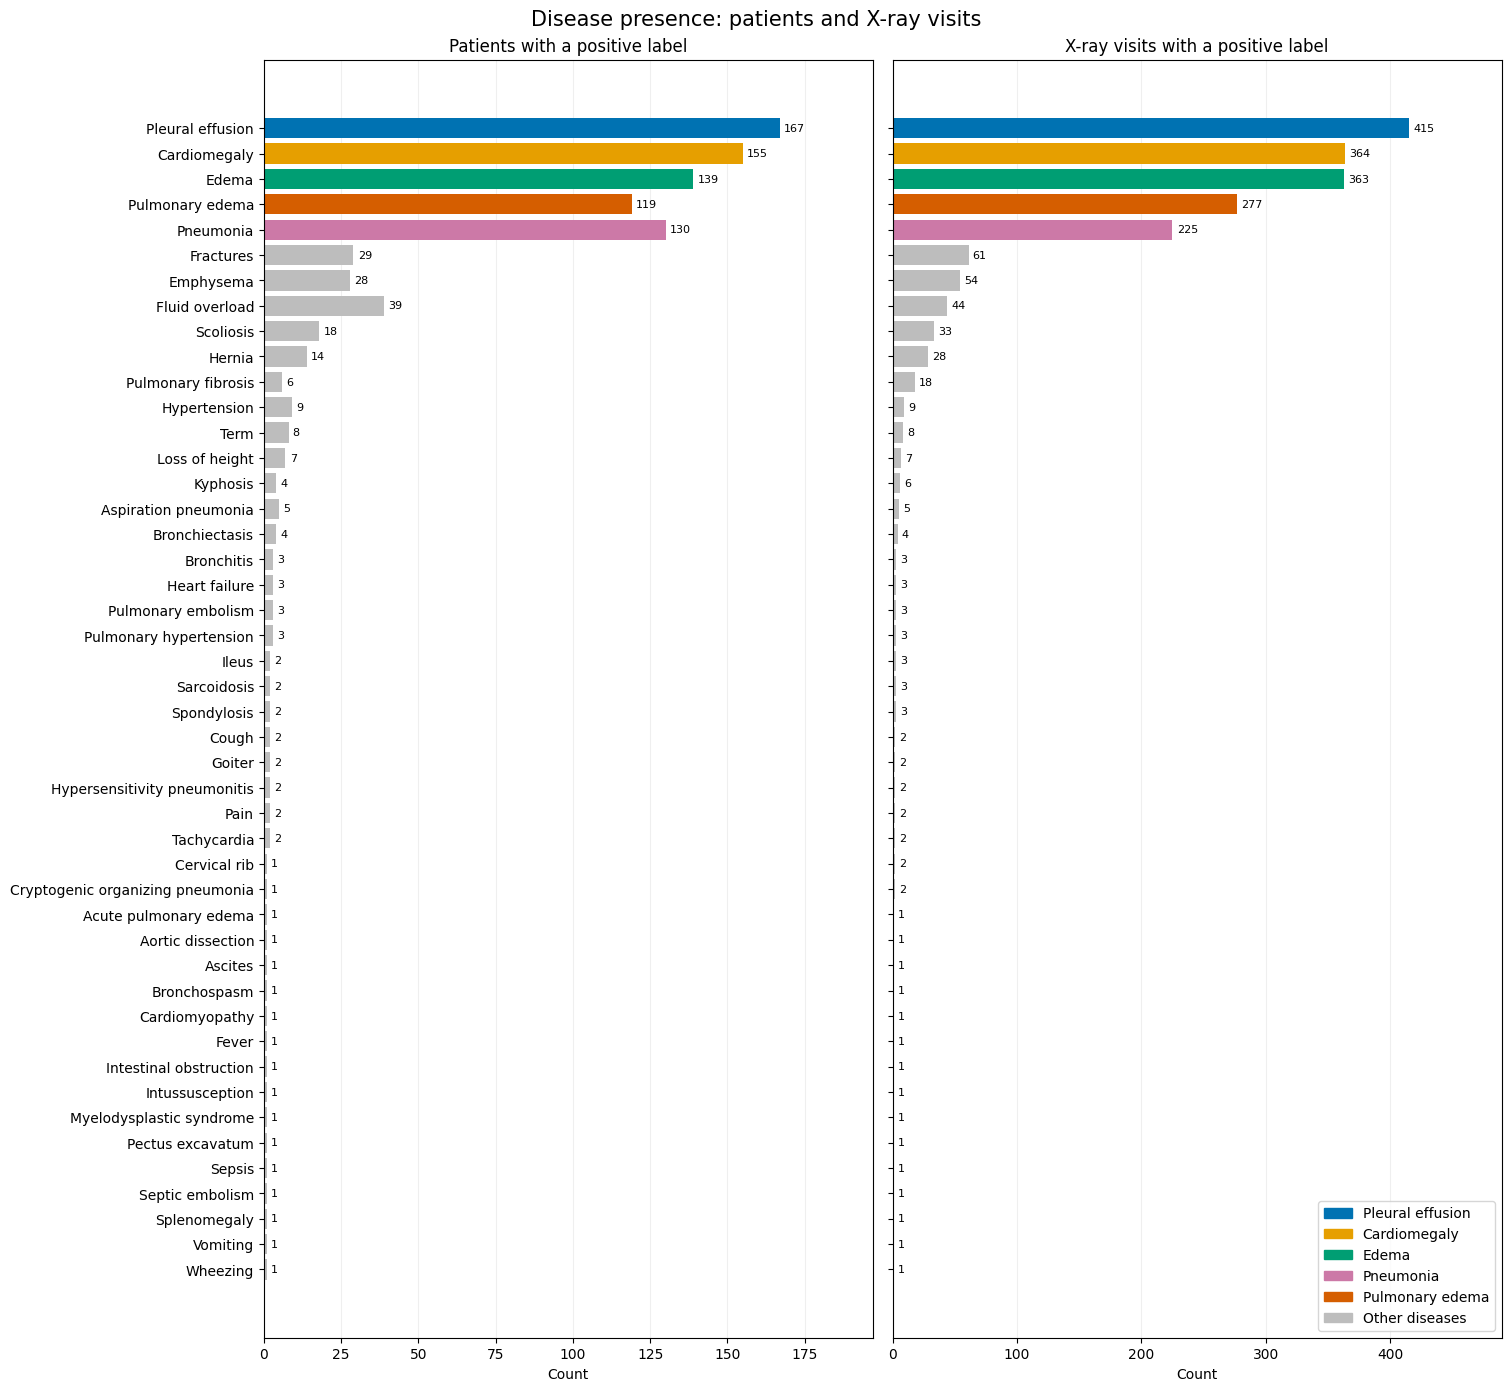

In [8]:
# Include every disease with at least one positive visit.
# Five selected diseases have distinct colors; other diseases are gray.
disease_colors = dict(zip(DISEASES, ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00"]))
positive_counts = diagnosis_counts.loc[diagnosis_counts["positive_report_count"] > 0].copy()
positive_counts = positive_counts.sort_values("positive_report_count", ascending=False)
if positive_counts.empty:
    print("No positive disease counts to plot.")
else:
    colors = [disease_colors.get(d, "#BDBDBD") for d in positive_counts["disease"]]
    fig, axes = plt.subplots(1, 2, figsize=(15, max(5, len(positive_counts) * 0.30)), sharey=True, layout="constrained")
    for ax, column, title in zip(axes, ["positive_patient_count", "positive_report_count"],
                                ["Patients with a positive label", "X-ray visits with a positive label"]):
        bars = ax.barh(positive_counts["disease"], positive_counts[column], color=colors)
        ax.bar_label(bars, padding=3, fontsize=8)
        ax.set_title(title)
        ax.set_xlabel("Count")
        ax.set_xlim(0, max(positive_counts[column].max() * 1.18, 1))
        ax.grid(axis="x", alpha=0.2)
        ax.set_axisbelow(True)
    axes[0].invert_yaxis()
    axes[1].legend(handles=[Patch(color=disease_colors[d], label=d) for d in DISEASES]
                   + [Patch(color="#BDBDBD", label="Other diseases")], loc="lower right")
    fig.suptitle("Disease presence: patients and X-ray visits", fontsize=15)
    plt.show()


## 4. Paired train, validation, and test loaders

Reuse the backbone's patient split CSV. Every unique pair has five labels; `-100` masks a disease without a usable label. Each model sees the same pair manifest. The DICOM loader currently decodes images on demand without an image cache.


In [9]:
if not SPLIT_CSV.is_file():
    raise FileNotFoundError(f"Existing backbone patient splits are required: {SPLIT_CSV}")
if REBUILD_PAIRS or REBUILD_LABELS or not PAIR_CSV.exists():
    prepare_pair_csv(
        pairs_csv=HYBRID_DIR / "prognosis_pairs.csv",
        split_csv=SPLIT_CSV, reports_root=REPORTS_ROOT, output_csv=PAIR_CSV,
        use_candidates=USE_CANDIDATES,
    )
pair_loaders = make_pair_loaders(PAIR_CSV, batch_size=PAIR_BATCH_SIZE)
pair_manifest = pd.read_csv(PAIR_CSV)
pair_summary = []
for split, group in pair_manifest.groupby("split"):
    for disease in DISEASES:
        counts = group[disease].value_counts()
        pair_summary.append({"split": split, "disease": disease,
                             **{label: int(counts.get(i, 0)) for i, label in enumerate(CLASS_NAMES)},
                             "masked": int(counts.get(-100, 0))})
display(pd.DataFrame(pair_summary))


train: 704 pairs, 212 patients
val: 92 pairs, 40 patients
test: 119 pairs, 39 patients


,split,disease,improving,stable,worsening,masked
0,test,Pleural effusion,10,24,21,64
1,test,Cardiomegaly,1,47,9,62
2,test,Edema,12,6,10,91
3,test,Pneumonia,7,0,5,107
4,test,Pulmonary edema,11,6,10,92
5,train,Pleural effusion,75,111,145,373
6,train,Cardiomegaly,15,311,25,353
7,train,Edema,77,32,66,529
8,train,Pneumonia,29,8,64,603
9,train,Pulmonary edema,71,33,65,535


### Progression-label distribution

Counts come from the actual pair manifest, across all splits. Masked labels (`-100`), including unusable mixed/no-comparison targets, are excluded. A pair can contribute to several diseases.


,improving,stable,worsening
Pleural effusion,94,140,180
Cardiomegaly,17,406,39
Edema,100,40,87
Pneumonia,41,11,77
Pulmonary edema,93,41,84


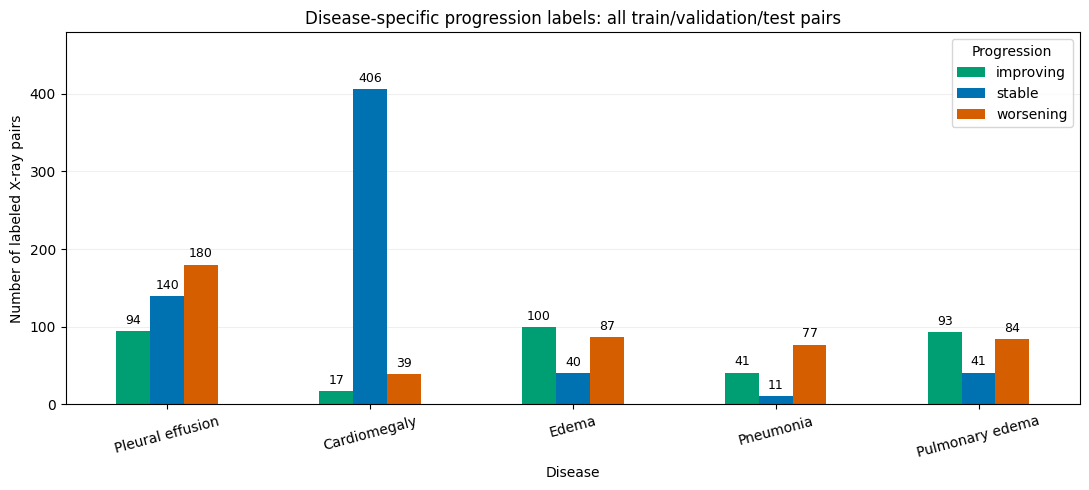

In [10]:
# Count the exact labels passed to the loaders, across all patient splits.
progression_plot_counts = pd.DataFrame({
    disease: [(pair_manifest[disease] == i).sum() for i in range(len(CLASS_NAMES))]
    for disease in DISEASES
}, index=CLASS_NAMES).T
if pair_manifest.duplicated(["subject_id", "input_study_id", "target_study_id"]).any():
    raise ValueError("Duplicate study pairs in the manifest; check before counting.")
display(progression_plot_counts)
ax = progression_plot_counts.plot.bar(
    figsize=(11, 5), color=["#009E73", "#0072B2", "#D55E00"], rot=15,
)
for bars in ax.containers:
    ax.bar_label(bars, padding=3, fontsize=9)
ax.set(title="Disease-specific progression labels: all train/validation/test pairs",
       xlabel="Disease", ylabel="Number of labeled X-ray pairs")
ax.margins(y=0.18)
ax.legend(title="Progression")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


## 5. Optional diagnosis-backbone training

Enable `RUN_BACKBONE` to train the original five-disease, four-state diagnosis model. Otherwise use the existing checkpoint. This is separate from paired progression training.


In [13]:
if RUN_BACKBONE:
    backbone_loaders = make_backbone_dataloaders(
        labels_csv=LABELS_PATH, reviews_csv=REVIEWS_PATH,
        report_summary_csv=DIAGNOSIS_DIR / "report_summary.csv", split_csv=SPLIT_CSV,
        reports_root=REPORTS_ROOT, batch_size=16, num_workers=24,
        manifest_path=LABELLING_DIR / "backbone_image_manifest.csv",
    )
    torch.manual_seed(SEED)
    diagnosis_model = CXRBackbone(pretrained=True)
    backbone_results = train_backbone(
        diagnosis_model, backbone_loaders, new_run("backbone"), epochs=EPOCHS,
        learning_rate=LEARNING_RATE, seed=SEED, device=DEVICE,
    )
    CHECKPOINT_PATH = backbone_results["best_path"]
    diagnosis_model.cpu()
    del diagnosis_model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
else:
    print("Using existing diagnosis checkpoint:", CHECKPOINT_PATH)


train studies: 2008 patients: 354
val studies: 307 patients: 74
test studies: 392 patients: 77
Excluded: {'unusable_report': 150}
Device: cuda | Epochs: 20 | Learning rate: 0.0001
Starting epoch 1/20: 126 training batches, 20 validation batches. Waiting for first batch...
Epoch 01/20 validation: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20/20 [00:03<00:00,  5.01batch/s, accuracy=73.2%, compute_s=0, data_s=4, loss=0.7238]
Epoch 01/20 | train loss 0.8341 | val loss 0.7238 | train accuracy 69.9% | val accuracy 73.2% | 24s | saved best
Starting epoch 2/20: 126 training batches, 20 validation batches. Waiting for first batch...
Epoch 02/20 validation: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20/20 [00:04<00:00,  4.94batch/s, accuracy=

## 6. Frozen-feature baseline: diagnosis checkpoint + PCA + logistic regression

This reproduces Roger's feature-difference approach with our five disease-specific three-class targets. DenseNet stays frozen; each disease gets its own PCA and classifier. Validation selects regularization. This is a baseline, not end-to-end fine-tuning.


In [14]:
if RUN_FROZEN_BASELINE:
    frozen_results = train_progression(
        checkpoint_path=CHECKPOINT_PATH, pair_loaders=pair_loaders,
        out_dir=new_run("paired_frozen_pca"), pca_components=50,
        c_values=(0.1, 0.5, 1.0, 10.0), seed=SEED, device=DEVICE,
    )
    display(pd.read_csv(frozen_results["out_dir"] / "metrics.csv"))
else:
    print("Set RUN_FROZEN_BASELINE=True to run this experiment.")


Device: cuda | Backbone: frozen | Labels: ('improving', 'stable', 'worsening')


test: paired features: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 15/15 [00:25<00:00,  1.69s/batch]


Pleural effusion: 331 train pairs | C=0.1 | test={'n_pairs': 55, 'accuracy': 0.38181818181818183, 'macro_f1': 0.38650793650793647, 'confusion_matrix': [[6, 2, 2], [6, 8, 10], [6, 8, 7]], 'improving_support': 10, 'improving_auroc': 0.6244444444444445, 'improving_auprc': 0.2716043791987188, 'stable_support': 24, 'stable_auroc': 0.5174731182795699, 'stable_auprc': 0.4496509343043445, 'worsening_support': 21, 'worsening_auroc': 0.48739495798319327, 'worsening_auprc': 0.41106032389168584, 'macro_auroc': 0.5431041735690693}
Cardiomegaly: 351 train pairs | C=0.1 | test={'n_pairs': 57, 'accuracy': 0.6140350877192983, 'macro_f1': 0.29106753812636166, 'confusion_matrix': [[0, 1, 0], [6, 34, 7], [0, 8, 1]], 'improving_support': 1, 'improving_auroc': 0.5, 'improving_auprc': 0.034482758620689655, 'stable_support': 47, 'stable_auroc': 0.35106382978723405, 'stable_auprc': 0.7743308133565753, 'worsening_support': 9, 'worsening_auroc': 0.5185185185185185, 'worsening_auprc': 0.18557195619962985, 'macro_

,disease,split,n_pairs,accuracy,macro_f1,improving_support,improving_auroc,improving_auprc,stable_support,stable_auroc,stable_auprc,worsening_support,worsening_auroc,worsening_auprc,macro_auroc
0,Pleural effusion,val,28,0.535714,0.511905,9,0.929825,0.870932,5,0.582609,0.283112,14,0.795918,0.818501,0.769451
1,Pleural effusion,test,55,0.381818,0.386508,10,0.624444,0.271604,24,0.517473,0.449651,21,0.487395,0.411060,0.543104
2,Cardiomegaly,val,54,0.666667,0.346899,1,0.150943,0.021739,48,0.579861,0.929316,5,0.722449,0.196068,0.484418
3,Cardiomegaly,test,57,0.614035,0.291068,1,0.500000,0.034483,47,0.351064,0.774331,9,0.518519,0.185572,0.456527
4,Edema,val,24,0.708333,0.527536,11,0.846154,0.741019,2,0.681818,0.171429,11,0.888112,0.918226,0.805361
5,Edema,test,28,0.714286,0.682336,12,0.807292,0.705866,6,0.750000,0.651557,10,0.850000,0.854815,0.802431
6,Pneumonia,val,16,0.437500,0.318519,5,0.527273,0.484156,3,0.666667,0.361111,8,0.546875,0.639649,0.580271
7,Pneumonia,test,12,0.666667,0.464646,7,0.657143,0.693290,0,NaN,NaN,5,0.714286,0.707576,NaN
8,Pulmonary edema,val,22,0.727273,0.520129,11,0.834711,0.795312,2,0.775000,0.242857,9,0.854701,0.876443,0.821471
9,Pulmonary edema,test,27,0.703704,0.645614,11,0.812500,0.703045,6,0.738095,0.532407,10,0.852941,0.860525,0.801179


## 7. Paired progression fine-tuning from the diagnosis checkpoint

Load the diagnosis encoder weights, attach a fresh five-disease progression head, and update **all encoder and head weights** on image pairs. Both images pass through the shared DenseNet; their feature difference produces a `[batch, 5, 3]` prediction tensor. Use masked cross-entropy and select the best checkpoint by validation loss.


Learning rates start at `1e-5` for the backbone and `1e-4` for the head. Cosine decay reaches 10% of each rate in the final epoch. Each epoch records both rates in `history.csv`.


In [17]:


def with_workers(loaders, workers=16):
    return {name: DataLoader(l.dataset, batch_size=l.batch_size, shuffle=(name == "train"),
                             num_workers=workers, pin_memory=torch.cuda.is_available(),
                             persistent_workers=workers > 0, prefetch_factor=4 if workers > 0 else None,
                             generator=torch.Generator().manual_seed(42) if name == "train" else None)
            for name, l in loaders.items()}

pair_loaders = with_workers(pair_loaders, workers=16)
print({k: (len(v.dataset), v.num_workers) for k, v in pair_loaders.items()})
if RUN_PAIRED_FINETUNE:
    finetune_results = train_paired_progression(
        pair_loaders=pair_loaders, out_dir=new_run("paired_finetune"),
        diagnosis_checkpoint=CHECKPOINT_PATH, epochs=EPOCHS,
        backbone_lr=FINETUNE_BACKBONE_LR, head_lr=FINETUNE_HEAD_LR,
        final_lr_ratio=FINAL_LR_RATIO, seed=SEED, device=DEVICE,
    )
    display(pd.DataFrame(finetune_results["metrics"]))
else:
    print("Set RUN_PAIRED_FINETUNE=True to fine-tune from the diagnosis checkpoint.")


{'train': (704, 16), 'val': (92, 16), 'test': (119, 16)}
Device: cuda | Initialization: diagnosis_checkpoint | All backbone layers trainable
Cosine schedule: backbone 1e-05 -> 1e-06; head 0.0001 -> 1e-05
1/20 val: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 12/12 [00:03<00:00,  3.97batch/s, loss=1.0721]
Epoch 1/20: train=1.1300, val=1.0721; backbone_lr=1.00e-05, head_lr=1.00e-04; best=1
2/20 val: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 12/12 [00:02<00:00,  4.80batch/s, loss=1.0245]
Epoch 2/20: train=0.9729, val=1.0245; backbone_lr=9.94e-06, head_lr=9.94e-05; best=2
3/20 val: 100%|███████████████████████████████████████████████

,disease,split,n_pairs,accuracy,macro_f1,improving_support,stable_support,worsening_support
0,Pleural effusion,val,28,0.642857,0.513580,9,5,14
1,Cardiomegaly,val,54,0.407407,0.283660,1,48,5
2,Edema,val,24,0.708333,0.514838,11,2,11
3,Pneumonia,val,16,0.562500,0.542735,5,3,8
4,Pulmonary edema,val,22,0.681818,0.600373,11,2,9
5,Pleural effusion,test,55,0.381818,0.375104,10,24,21
6,Cardiomegaly,test,57,0.438596,0.235431,1,47,9
7,Edema,test,28,0.678571,0.579012,12,6,10
8,Pneumonia,test,12,0.250000,0.195286,7,0,5
9,Pulmonary edema,test,27,0.666667,0.573077,11,6,10


## 8. Paired progression training from scratch

Use the **same trainable architecture, labels, patient splits, and epoch count** as Section 7, starting with random weights. No diagnosis checkpoint or ImageNet weights are loaded. Both learning rates start at `1e-4` and decay to `1e-5`. This comparison differs in both initialization and backbone learning rate; it is not an initialization-only ablation. Each experiment resets its seed and training-loader shuffle generator.


In [18]:
def with_workers(loaders, workers=16):
    return {name: DataLoader(l.dataset, batch_size=l.batch_size, shuffle=(name == "train"),
                             num_workers=workers, pin_memory=torch.cuda.is_available(),
                             persistent_workers=workers > 0, prefetch_factor=4 if workers > 0 else None,
                             generator=torch.Generator().manual_seed(42) if name == "train" else None)
            for name, l in loaders.items()}

pair_loaders = with_workers(pair_loaders, workers=16)
print({k: (len(v.dataset), v.num_workers) for k, v in pair_loaders.items()})
if RUN_PAIRED_SCRATCH:
    scratch_results = train_paired_progression(
        pair_loaders=pair_loaders, out_dir=new_run("paired_scratch"),
        diagnosis_checkpoint=None, epochs=EPOCHS,
        backbone_lr=SCRATCH_BACKBONE_LR, head_lr=SCRATCH_HEAD_LR,
        final_lr_ratio=FINAL_LR_RATIO, seed=SEED, device=DEVICE,
    )
    display(pd.DataFrame(scratch_results["metrics"]))
else:
    print("Set RUN_PAIRED_SCRATCH=True to train the paired model from random weights.")


{'train': (704, 16), 'val': (92, 16), 'test': (119, 16)}
Device: cuda | Initialization: random | All backbone layers trainable
Cosine schedule: backbone 0.0001 -> 1e-05; head 0.0001 -> 1e-05
1/20 val: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 12/12 [00:02<00:00,  4.09batch/s, loss=1.0542]
Epoch 1/20: train=1.1074, val=1.0542; backbone_lr=1.00e-04, head_lr=1.00e-04; best=1
2/20 val: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 12/12 [00:02<00:00,  4.64batch/s, loss=1.0433]
Epoch 2/20: train=1.0473, val=1.0433; backbone_lr=9.94e-05, head_lr=9.94e-05; best=2
3/20 val: 100%|████████████████████████████████████████████████████████████

,disease,split,n_pairs,accuracy,macro_f1,improving_support,stable_support,worsening_support
0,Pleural effusion,val,28,0.500000,0.467033,9,5,14
1,Cardiomegaly,val,54,0.425926,0.267399,1,48,5
2,Edema,val,24,0.708333,0.502024,11,2,11
3,Pneumonia,val,16,0.312500,0.246212,5,3,8
4,Pulmonary edema,val,22,0.681818,0.501684,11,2,9
5,Pleural effusion,test,55,0.363636,0.356229,10,24,21
6,Cardiomegaly,test,57,0.421053,0.274074,1,47,9
7,Edema,test,28,0.535714,0.412698,12,6,10
8,Pneumonia,test,12,0.666667,0.488889,7,0,5
9,Pulmonary edema,test,27,0.518519,0.403810,11,6,10


## 9. Compare completed experiments

Use validation results to make model choices. Test results are held-out descriptions, not a tuning signal. Macro F1 includes all three classes; consult class supports where a disease has few or no examples of one class. This table compares frozen classifiers with two end-to-end neural models, so the frozen baseline also differs in architecture/training method.


In [19]:
comparison_tables = []
for result_name, experiment in [
    ("frozen_results", "Frozen diagnosis features + PCA/LR"),
    ("finetune_results", "Paired fine-tuning from diagnosis"),
    ("scratch_results", "Paired training from scratch"),
]:
    result = globals().get(result_name)
    if result is not None:
        table = pd.read_csv(result["out_dir"] / "metrics.csv")
        table.insert(0, "experiment", experiment)
        comparison_tables.append(table)
if comparison_tables:
    experiment_comparison = pd.concat(comparison_tables, ignore_index=True)
    display(experiment_comparison[["experiment", "disease", "split", "n_pairs", "accuracy", "macro_f1"]])
else:
    print("Enable and run an experiment to populate this table.")


,experiment,disease,split,n_pairs,accuracy,macro_f1
0,Frozen diagnosis features + PCA/LR,Pleural effusion,val,28,0.535714,0.511905
1,Frozen diagnosis features + PCA/LR,Pleural effusion,test,55,0.381818,0.386508
2,Frozen diagnosis features + PCA/LR,Cardiomegaly,val,54,0.666667,0.346899
3,Frozen diagnosis features + PCA/LR,Cardiomegaly,test,57,0.614035,0.291068
4,Frozen diagnosis features + PCA/LR,Edema,val,24,0.708333,0.527536
5,Frozen diagnosis features + PCA/LR,Edema,test,28,0.714286,0.682336
6,Frozen diagnosis features + PCA/LR,Pneumonia,val,16,0.437500,0.318519
7,Frozen diagnosis features + PCA/LR,Pneumonia,test,12,0.666667,0.464646
8,Frozen diagnosis features + PCA/LR,Pulmonary edema,val,22,0.727273,0.520129
9,Frozen diagnosis features + PCA/LR,Pulmonary edema,test,27,0.703704,0.645614


## 10. Experiment confusion matrices

Load saved validation/test evaluations without training again. Each panel is disease-specific: rows are actual labels, columns are predictions. Cells show counts and percentages within the actual class; N/A means that class has no examples. Colors use the same 0–100% scale in every panel. The selected run folder is printed; override it below to compare particular runs.


Frozen diagnosis features + PCA/LR: /scratch/users/nus/e1583516/BN5212/Group Project/midterm_prognosis/training_outputs/paired_frozen_pca_20261029_092858_469158


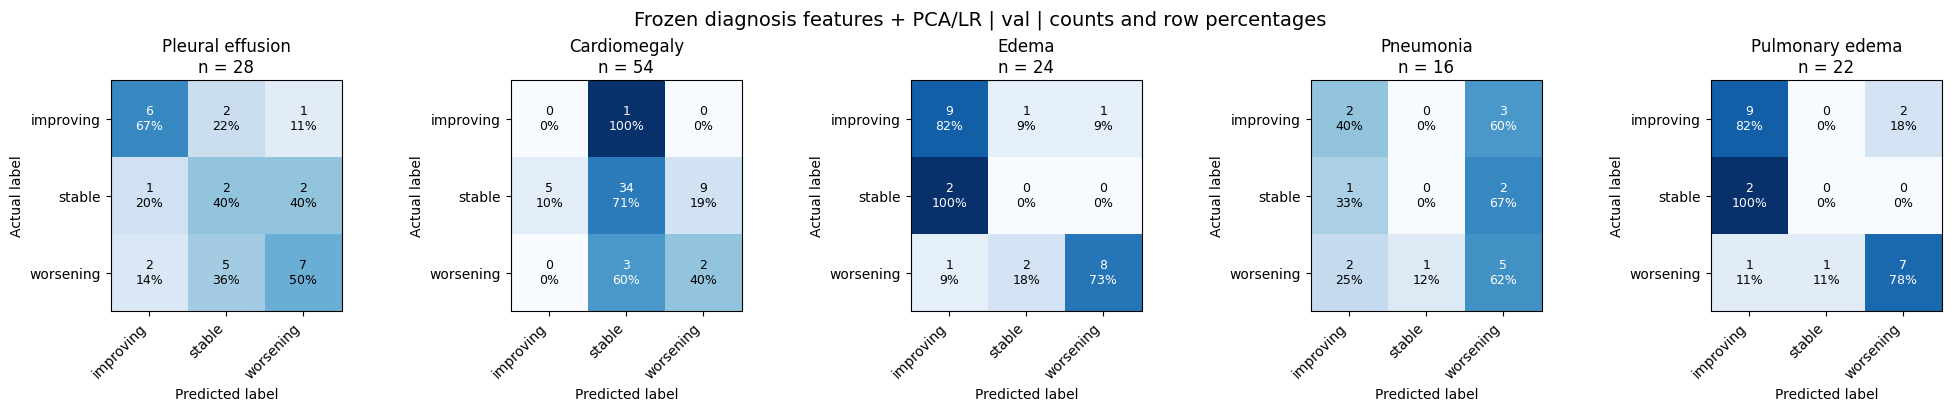

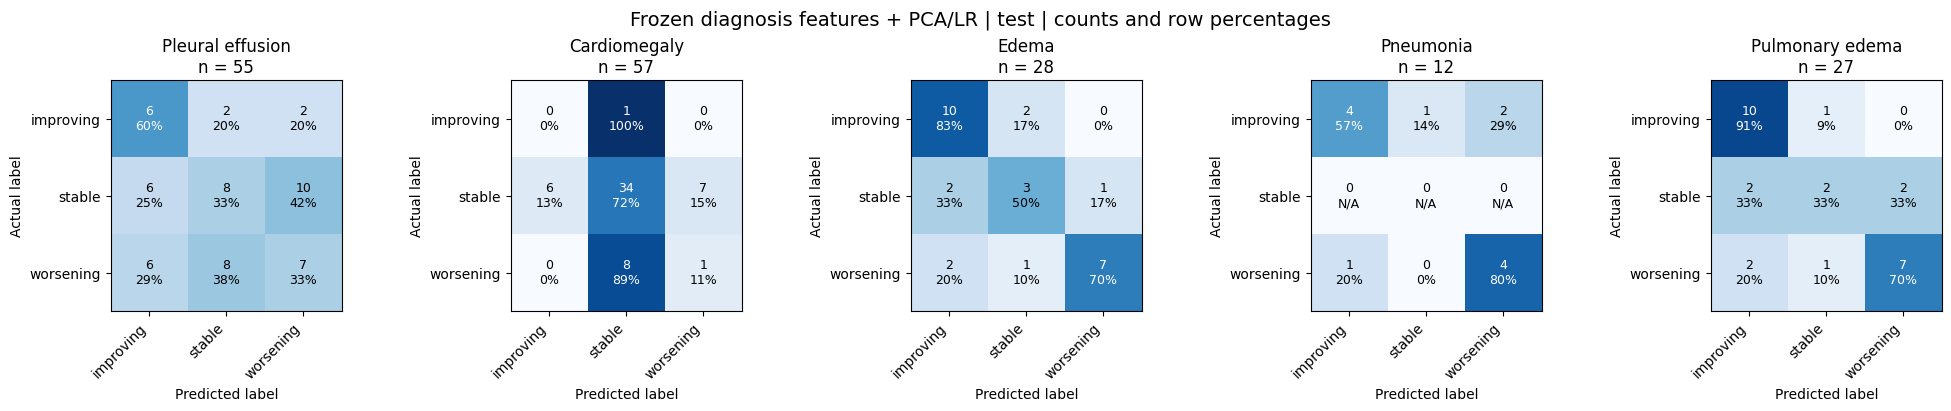

Paired fine-tuning from diagnosis: /scratch/users/nus/e1583516/BN5212/Group Project/midterm_prognosis/training_outputs/paired_finetune_20261029_093956_735123


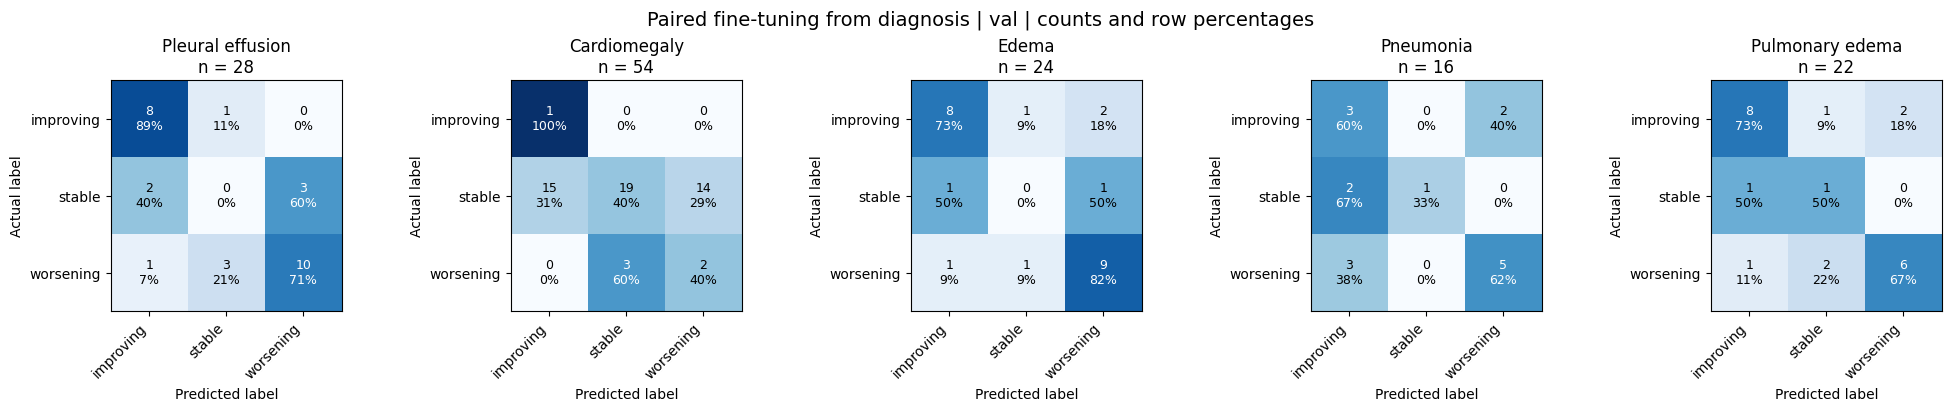

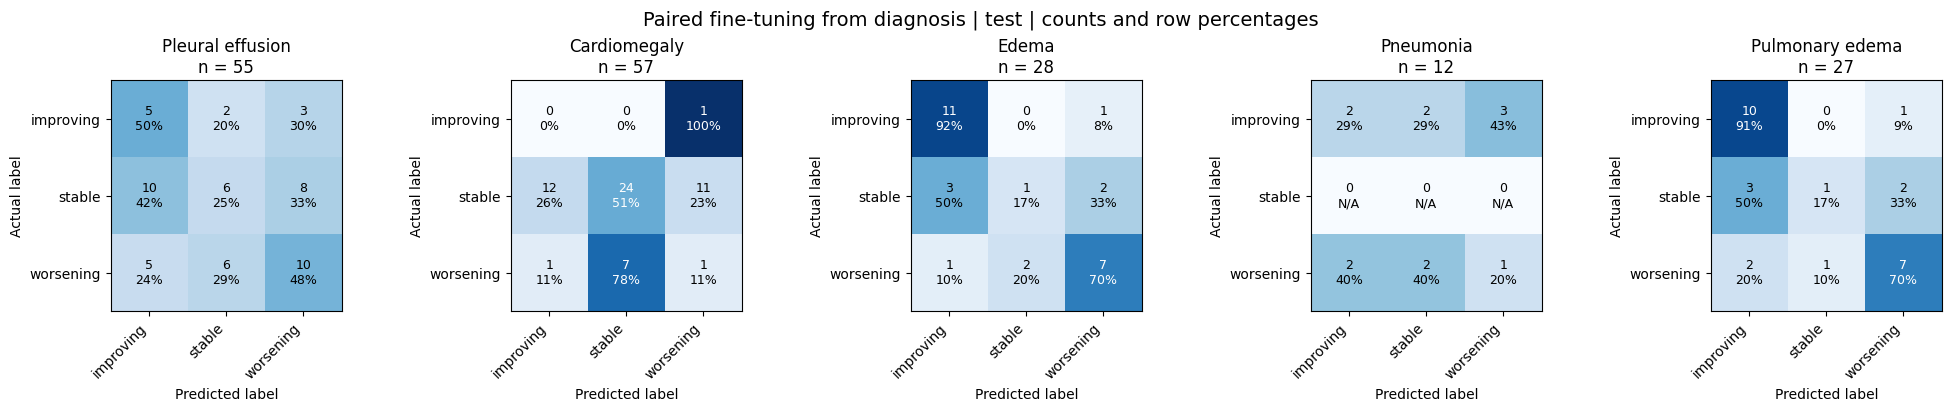

Paired training from scratch: /scratch/users/nus/e1583516/BN5212/Group Project/midterm_prognosis/training_outputs/paired_scratch_20261029_094820_270618


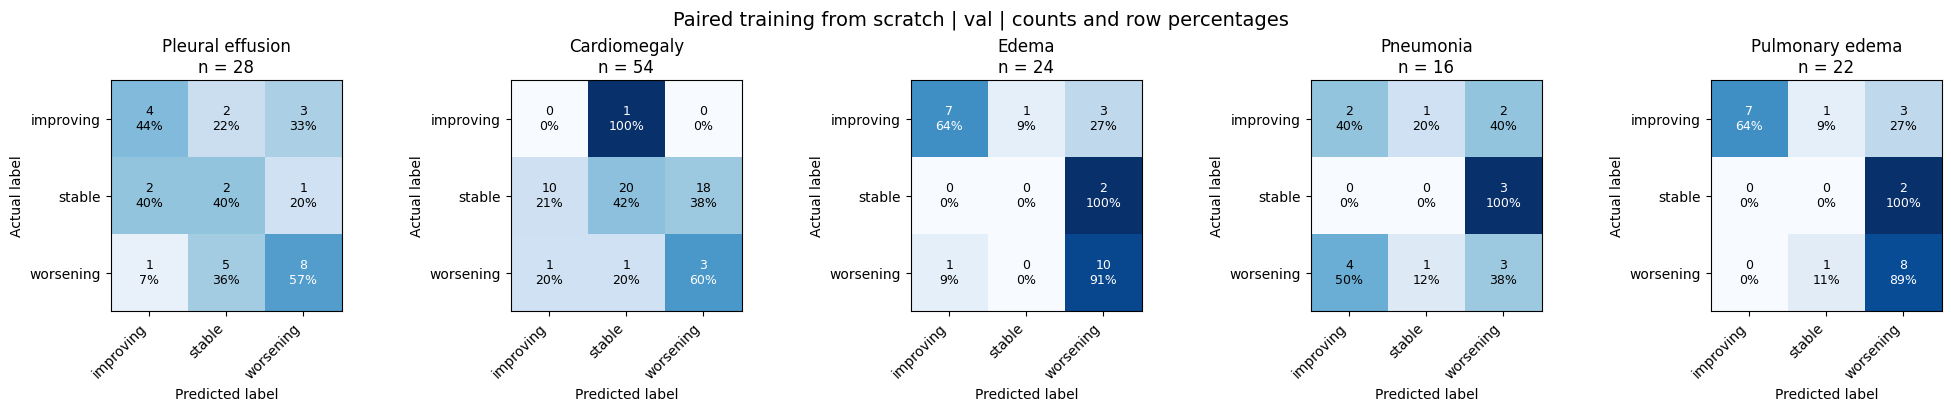

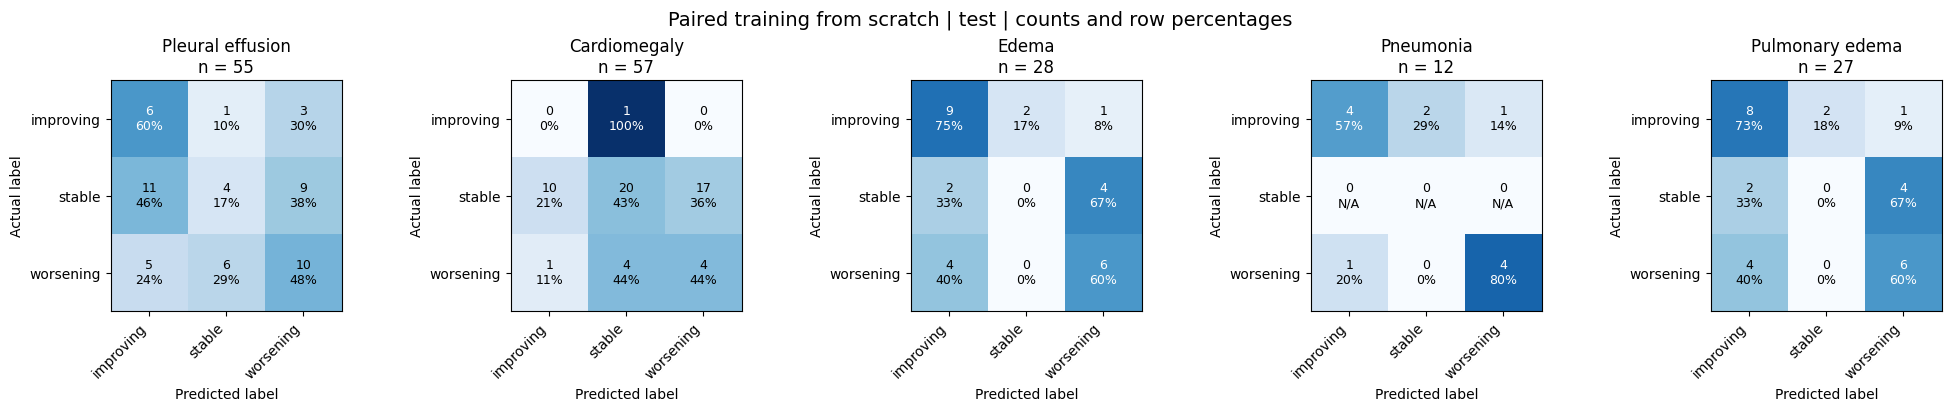

In [20]:
# Optional: set a folder explicitly to compare specific saved runs.
# None uses this session's result, then the latest completed saved run.
CONFUSION_RUN_DIRS = {
    "Frozen diagnosis features + PCA/LR": None,
    "Paired fine-tuning from diagnosis": None,
    "Paired training from scratch": None,
}
CONFUSION_SPLITS = ["val", "test"]
experiment_sources = [
    ("Frozen diagnosis features + PCA/LR", "frozen_results", "paired_frozen_pca_*", "metrics.json"),
    ("Paired fine-tuning from diagnosis", "finetune_results", "paired_finetune_*", "confusion_matrices.json"),
    ("Paired training from scratch", "scratch_results", "paired_scratch_*", "confusion_matrices.json"),
]
for experiment, result_name, pattern, filename in experiment_sources:
    run_dir = CONFUSION_RUN_DIRS[experiment]
    if run_dir is None:
        result = globals().get(result_name)
        if result is not None:
            run_dir = result["out_dir"]
        else:
            completed = sorted(p for p in (PROJECT_DIR / "training_outputs").glob(pattern)
                               if (p / filename).is_file())
            run_dir = completed[-1] if completed else None
    if run_dir is None:
        print(f"{experiment}: no completed results yet.")
        continue
    run_dir = Path(run_dir)
    source = run_dir / filename
    if not source.is_file():
        print(f"Missing saved results: {source}")
        continue
    print(f"{experiment}: {run_dir}")
    saved = json.loads(source.read_text(encoding="utf-8"))
    settings_file = run_dir / "settings.json"
    settings = json.loads(settings_file.read_text(encoding="utf-8")) if settings_file.exists() else {}
    saved_diseases = settings.get("diseases", DISEASES)
    saved_classes = settings.get("labels", CLASS_NAMES)
    if list(saved_classes) != CLASS_NAMES:
        raise ValueError(f"Unexpected class order in {run_dir}: {saved_classes}")
    for split in CONFUSION_SPLITS:
        fig, axes = plt.subplots(1, len(DISEASES), figsize=(20, 4), layout="constrained", squeeze=False)
        for ax, disease in zip(axes[0], DISEASES):
            if filename == "metrics.json":
                matrix = saved.get("diseases", {}).get(disease, {}).get(split, {}).get("confusion_matrix")
            else:
                matrices = saved.get(split, {}).get("confusion")
                matrix = matrices[saved_diseases.index(disease)] if matrices is not None and disease in saved_diseases else None
            if matrix is None:
                ax.set_title(disease)
                ax.text(0.5, 0.5, "No saved evaluation", ha="center", va="center")
                ax.set_axis_off()
                continue
            matrix = np.asarray(matrix)
            if matrix.shape != (3, 3):
                raise ValueError(f"Invalid confusion matrix for {experiment}, {disease}, {split}")
            support = matrix.sum(axis=1, keepdims=True)
            fractions = np.divide(matrix, support, out=np.zeros((3, 3), dtype=float), where=support != 0)
            ax.imshow(fractions, vmin=0, vmax=1, cmap="Blues")
            for i in range(3):
                for j in range(3):
                    annotation = f"{int(matrix[i, j])}\n{fractions[i, j]:.0%}" if support[i, 0] else "0\nN/A"
                    ax.text(j, i, annotation, ha="center", va="center",
                            color="white" if fractions[i, j] > 0.5 else "black", fontsize=9)
            ax.set_xticks(range(3), CLASS_NAMES, rotation=45, ha="right")
            ax.set_yticks(range(3), CLASS_NAMES)
            ax.set(title=f"{disease}\nn = {int(matrix.sum())}", xlabel="Predicted label", ylabel="Actual label")
        fig.suptitle(f"{experiment} | {split} | counts and row percentages", fontsize=14)
        plt.show()


## 11. Extensions: stronger image encoder and MIMIC-IV features

Code lives in `longitudinal_ext/` (copy the folder next to `model/` and `data_loader/`; nothing existing is modified).
All runs below use the **same pair manifest and patient splits** as Sections 6-8, and write `metrics.csv`,
`confusion_matrices.json`, `settings.json` in the same layout, so Sections 9-10 tools still work.

Order: (a) build/inspect MIMIC-IV features and **check coverage**, (b) tabular-only baseline, (c) screen encoders with
frozen features (cheap), (d) fine-tune the 2x2 ablation {baseline encoder, new encoder} x {image, image+tabular}.

Leakage rule: only events at or before each study time are used; ICD diagnoses, discharge data and death dates are never used.
Encoders pretrained on MIMIC-CXR (`xrv:...-all`, `hf:microsoft/rad-dino`) may have seen your test patients; the default
`xrv:densenet121-res224-chex` was not trained on MIMIC-CXR.

### 11.0 MIMIC-IV tables from zip

MIMIC-IV is still inside `MIMIC-IV.zip`. Run this once: `"dry_run"` lists the tables found in the zip and their sizes (seconds), then `"extract"` writes them to `DATA_ROOT/MIMIC-IV/3.1/hosp|icu/` (resumable: finished files are skipped). Building the features afterwards reads `labevents` and `chartevents` in chunks and can take a while on the first run; results are cached.

In [21]:
# ---- 11.0  Extract the MIMIC-IV tables used for the features from MIMIC-IV.zip (skip if hosp/ and icu/ are already extracted)
MIMIC_IV_EXTRACT = "extract"        # "off"  |  "dry_run" (list what would be extracted, takes seconds)  |  "extract"
MIMIC_IV_ZIP = BN5212_DATA_DIR / "MIMIC-IV.zip"
MIMIC_IV_DEST = DATA_ROOT / "MIMIC-IV" / "3.1"            # must equal MIMIC_IV_ROOT below
MIMIC_IV_TABLES = {                                         # remove a table to skip it (chartevents is by far the largest: vitals)
    "hosp": ["patients", "admissions", "d_labitems", "labevents", "prescriptions", "d_icd_diagnoses"],
    "icu":  ["icustays", "d_items", "chartevents", "inputevents", "outputevents"],
}

def extract_mimic_iv(zip_path, dest, tables, dry_run=True, chunk=16 * 1024 * 1024):
    import io, re, shutil, struct, zipfile
    from collections import Counter

    class _Win(io.RawIOBase):                                # seekable view of a stored nested zip, read in place
        def __init__(self, path, start, size): self.f, self.s, self.n, self.p = open(path, "rb"), start, size, 0
        def readable(self): return True
        def seekable(self): return True
        def tell(self): return self.p
        def seek(self, o, w=io.SEEK_SET):
            self.p = max(0, min(o if w == io.SEEK_SET else self.p + o if w == io.SEEK_CUR else self.n + o, self.n)); return self.p
        def readinto(self, b):
            k = min(len(b), self.n - self.p)
            if k <= 0: return 0
            self.f.seek(self.s + self.p); d = self.f.read(k); b[:len(d)] = d; self.p += len(d); return len(d)
        def close(self):
            if not self.closed: self.f.close()
            super().close()

    def archives(path):                                      # the zip itself + any stored nested zip (one level)
        outer = zipfile.ZipFile(path); yield str(path), outer
        for info in outer.infolist():
            if info.filename.lower().endswith(".zip"):
                if info.compress_type != zipfile.ZIP_STORED:
                    print(f"  cannot read compressed nested zip in place: {info.filename} ({info.file_size/1e9:.2f} GB)"); continue
                with open(path, "rb") as r:
                    r.seek(info.header_offset); h = r.read(30)
                n, e = struct.unpack("<HH", h[26:30])
                w = _Win(path, info.header_offset + 30 + n + e, info.file_size); z = zipfile.ZipFile(w)
                yield f"{path.name}::{info.filename}", z; z.close(); w.close()
        outer.close()

    module_of = {t: m for m, ts in tables.items() for t in ts}
    other_modules = {"ed", "note", "ecg", "cxr", "hosp", "icu"}
    rx = re.compile(r"(?:^|/)(?:([^/]+)/)?([a-z0-9_]+)\.csv(?:\.gz)?$", re.I)
    found, seen = {}, []                                     # table -> (label, info)
    zip_path = Path(zip_path)
    for label, z in archives(zip_path):
        names = z.infolist(); seen.append((label, names))
        for info in names:
            m = rx.search(info.filename)
            if not m: continue
            parent, tab = (m.group(1) or "").lower(), m.group(2).lower()
            if tab in module_of and tab not in found and (parent == module_of[tab] or parent not in other_modules):
                found[tab] = (label, info)
    total = 0
    with zipfile.ZipFile(zip_path) as outer:
        for tab, (label, info) in sorted(found.items(), key=lambda kv: (module_of[kv[0]], kv[0])):
            mod = module_of[tab]
            out = Path(dest) / mod / Path(info.filename).name
            state = "skip (already there)" if out.exists() and out.stat().st_size == info.file_size else ("would extract" if dry_run else "extracting")
            print(f"{mod}/{tab:<16} {info.file_size/1e9:6.2f} GB  {state}   <- {label} :: {info.filename}")
            total += info.file_size
            if not dry_run and state == "extracting":
                out.parent.mkdir(parents=True, exist_ok=True)
                tmp = out.with_suffix(out.suffix + ".part")
                for lab2, z2 in archives(zip_path):
                    if lab2 == label:
                        with z2.open(info) as src, open(tmp, "wb") as dst: shutil.copyfileobj(src, dst, chunk)
                        break
                tmp.rename(out)
    missing = sorted(set(module_of) - set(found))
    print(f"\ntables found: {len(found)}/{len(module_of)} | total {total/1e9:.1f} GB | missing: {missing or 'none'}")
    if not found:
        print("\nNo table matched. What is inside the zip (send this output):")
        for label, names in seen:
            print(f"- {label}: {len(names)} members; extensions: {dict(Counter(Path(i.filename).suffix.lower() or '(none)' for i in names).most_common(6))}")
            for i in names[:25]: print("    ", i.filename, f"({i.file_size/1e6:.1f} MB)")
    return found

if MIMIC_IV_EXTRACT in ("dry_run", "extract"):
    extract_mimic_iv(MIMIC_IV_ZIP, MIMIC_IV_DEST, MIMIC_IV_TABLES, dry_run=(MIMIC_IV_EXTRACT == "dry_run"))
else:
    print('Set MIMIC_IV_EXTRACT = "dry_run" (then "extract") to unpack the MIMIC-IV tables from the zip.')

hosp/admissions         0.09 GB  skip (already there)   <- MIMIC-IV.zip::MIMIC_IV.zip :: MIMIC_IV/physionet.org/files/mimiciv/3.1/hosp/admissions.csv
hosp/d_icd_diagnoses    0.01 GB  skip (already there)   <- MIMIC-IV.zip::MIMIC_IV.zip :: MIMIC_IV/physionet.org/files/mimiciv/3.1/hosp/d_icd_diagnoses.csv
hosp/d_labitems         0.00 GB  skip (already there)   <- MIMIC-IV.zip::MIMIC_IV.zip :: MIMIC_IV/physionet.org/files/mimiciv/3.1/hosp/d_labitems.csv
hosp/labevents         18.40 GB  skip (already there)   <- MIMIC-IV.zip::MIMIC_IV.zip :: MIMIC_IV/physionet.org/files/mimiciv/3.1/hosp/labevents.csv
hosp/patients           0.01 GB  skip (already there)   <- MIMIC-IV.zip::MIMIC_IV.zip :: MIMIC_IV/physionet.org/files/mimiciv/3.1/hosp/patients.csv
hosp/prescriptions      3.49 GB  skip (already there)   <- MIMIC-IV.zip::MIMIC_IV.zip :: MIMIC_IV/physionet.org/files/mimiciv/3.1/hosp/prescriptions.csv
icu/chartevents       30.05 GB  skip (already there)   <- MIMIC-IV.zip::MIMIC_IV.zip :: MIMIC_I

In [22]:
from longitudinal_ext.mimic_iv_features import build_pair_features, coverage_report
from longitudinal_ext.pair_data import detect_image_columns
from longitudinal_ext.experiments import run_experiment
from longitudinal_ext.tabular_baseline import run_tabular_baseline
from longitudinal_ext.reporting import collect, summary, plot_confusions

MIMIC_IV_ROOT = DATA_ROOT / "MIMIC-IV" / "3.1"               # needs hosp/ (labs, prescriptions, admissions, patients); icu/ optional
EXT_DIR = PROJECT_DIR / "extensions_outputs"
TAB_CSV = EXT_DIR / "pair_tabular_features.csv"
IMAGE_CACHE = EXT_DIR / "image_cache"                          # decoded DICOMs are cached here (huge speed-up)
RUNS_ROOT = PROJECT_DIR / "training_outputs"
EXT_SEEDS = [42]                         # final: [42, 43, 44]

BASE_ENCODER = "densenet121_imagenet"    # tetap: ini encoder repo
NEW_ENCODER = "hf:microsoft/rad-dino"    # isi dengan pemenang screening (validation)

RUN_TAB_BASELINE = True                  # sinyal fitur MIMIC-IV saja, tanpa gambar
RUN_ENCODER_SCREEN = True                # bandingkan semua encoder
EXT_TO_RUN = ["A_base_img", "A2_base_diag_img", "B_base_img_tab",
              "C_new_img", "D_new_img_tab", "E_new_img_tab_shuffled", "F_tab_nn"]


pair_df = pd.read_csv(PAIR_CSV)
IMG_IN, IMG_TG = detect_image_columns(pair_df)
print("image columns:", IMG_IN, "|", IMG_TG)
print("PAIR_CSV:", PAIR_CSV)
if not Path(str(pair_df[IMG_IN].iloc[0])).is_file():
    raise FileNotFoundError(f"PAIR_CSV has DICOM paths that do not exist on this machine:\n  {pair_df[IMG_IN].iloc[0]}\n"
                            "Run step 1b (extract DICOMs) and then the 'Path check and portability' cell, then re-run this cell.")
if not (MIMIC_IV_ROOT / "hosp").is_dir():
    raise FileNotFoundError(f"MIMIC-IV tables not found: {MIMIC_IV_ROOT / 'hosp'} (needs *.csv or *.csv.gz). "
                            "Set MIMIC_IV_ROOT to the folder that contains hosp/ and icu/.")

image columns: prior_dicom_path | current_dicom_path
PAIR_CSV: /scratch/users/nus/e1583516/BN5212/Group Project/midterm_prognosis/extensions_outputs/all_disease_pairs_local.csv


In [24]:
REBUILD_TAB = globals().get("REBUILD_TAB", False)
EXT_DIR.mkdir(parents=True, exist_ok=True)
if REBUILD_TAB or not TAB_CSV.exists():
    tab_features = build_pair_features(pair_df, IMG_IN, IMG_TG, MIMIC_IV_ROOT, EXT_DIR / "mimic_cache", TAB_CSV)
tab_features = pd.read_csv(TAB_CSV, dtype={"subject_id": str, "input_study_id": str, "target_study_id": str})
print("pairs:", len(tab_features), "| feature columns:", tab_features.shape[1] - 3)
display(coverage_report(tab_features, pair_df))   # 'delta' = share of pairs where cur AND prev exist

pairs: 915 | feature columns: 77


,cur,prev,delta
feature,,,
antibiotic_active,1.000,1.000,1.000
antibiotic_new24h,1.000,1.000,1.000
diuretic_active,1.000,1.000,1.000
diuretic_new24h,1.000,1.000,1.000
inpatient,1.000,1.000,1.000
icu,1.000,1.000,1.000
creatinine,0.795,0.786,0.690
bun,0.795,0.786,0.690
hemoglobin,0.793,0.785,0.690


In [25]:
if RUN_TAB_BASELINE:
    tab_only = run_tabular_baseline(PAIR_CSV, TAB_CSV, new_run("ext_tab_logreg"))
    display(pd.DataFrame(tab_only["metrics"]))
else:
    print("Set RUN_TAB_BASELINE=True: tabular-only signal check (no images).")

,disease,split,n_pairs,accuracy,balanced_accuracy,macro_f1
0,Pleural effusion,val,28,0.428571,0.355026,0.349393
1,Cardiomegaly,val,54,0.888889,0.333333,0.313725
2,Edema,val,24,0.541667,0.530303,0.459341
3,Pneumonia,val,16,0.500000,0.358333,0.307359
4,Pulmonary edema,val,22,0.545455,0.513468,0.452991
5,Pleural effusion,test,55,0.581818,0.546032,0.548806
6,Cardiomegaly,test,57,0.824561,0.333333,0.301282
7,Edema,test,28,0.285714,0.238889,0.250000
8,Pneumonia,test,12,0.833333,0.857143,0.555556
9,Pulmonary edema,test,27,0.444444,0.401010,0.395421


In [26]:
# ---- Multi-GPU: run different experiments on different GPUs in parallel (one job per GPU at a time).
from concurrent.futures import ThreadPoolExecutor
N_GPU = max(1, torch.cuda.device_count())
print("GPUs visible:", torch.cuda.device_count())

def run_parallel(jobs):
    """jobs: list of (key, fn(device) -> result). The first job runs alone to fill the image cache."""
    dev_of = (lambda i: f"cuda:{i}") if torch.cuda.is_available() else (lambda i: "cpu")
    results = {jobs[0][0]: jobs[0][1](dev_of(0))}
    rest = jobs[1:]
    lanes = [rest[i::N_GPU] for i in range(N_GPU)]
    def lane(i):
        return [(k, fn(dev_of(i))) for k, fn in lanes[i]]
    with ThreadPoolExecutor(max_workers=N_GPU) as ex:
        for out in ex.map(lane, range(N_GPU)):
            results.update(dict(out))
    return results


GPUs visible: 4


In [ ]:
from transformers import AutoImageProcessor, AutoModel
import open_clip, timm, torchvision

In [35]:
import sys
for k in [k for k in sys.modules if k.split(".")[0] in ("accelerate", "transformers")]:
    del sys.modules[k]
from transformers import AutoImageProcessor, AutoModel
import open_clip, timm, torchvision
print("OK")

OK


In [37]:
import importlib, transformers, open_clip.hf_model as _hm
importlib.reload(_hm)          # open_clip membaca ulang `transformers`
print("open_clip HF text encoder:", _hm.transformers is not None)

open_clip HF text encoder: True


In [38]:
# Encoder screening: frozen encoder -> (current - prior) -> PCA -> logistic regression. Minutes, not hours.
ENCODER_CANDIDATES = [
    "densenet121_imagenet",
    "xrv:densenet121-res224-chex",
    "xrv:densenet121-res224-nih",
    "hf:microsoft/rad-dino",            # pip install transformers
    "biomedclip",                       # pip install open_clip_torch
    "timm:convnext_small.fb_in22k_ft_in1k",   # pip install timm
]
screen_runs = {}
if RUN_ENCODER_SCREEN:
    jobs = [(enc, (lambda dev, enc=enc: run_experiment(
                "screen_" + enc.replace(":", "_").replace("/", "_"), manifest_csv=PAIR_CSV, out_root=RUNS_ROOT,
                encoder=enc, frozen_only=True, image_cache=IMAGE_CACHE, device=dev, seed=SEED)))
            for enc in ENCODER_CANDIDATES]
    for enc, r in run_parallel(jobs).items():
        screen_runs[enc] = [r["out_dir"]]
    display(summary(collect(screen_runs), split="val"))   # choose NEW_ENCODER on VALIDATION, not test
else:
    print("Set RUN_ENCODER_SCREEN=True to compare encoders with frozen features.")


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

,Pleural effusion,Cardiomegaly,Edema,Pneumonia,Pulmonary edema,mean_over_diseases,sd_over_seeds
experiment,,,,,,,
biomedclip,0.557,0.574,0.441,0.306,0.544,0.484,NaN
densenet121_imagenet,0.479,0.307,0.621,0.343,0.776,0.505,NaN
hf:microsoft/rad-dino,0.392,0.314,0.465,0.338,0.563,0.414,NaN
timm:convnext_small.fb_in22k_ft_in1k,0.229,0.369,0.408,0.307,0.414,0.345,NaN
xrv:densenet121-res224-chex,0.424,0.303,0.518,0.635,0.523,0.480,NaN
xrv:densenet121-res224-nih,0.558,0.361,0.653,0.561,0.742,0.575,NaN


In [39]:
EXT_EXPERIMENTS = {
    "A_base_img":             dict(encoder=BASE_ENCODER),
    "A2_base_diag_img":       dict(encoder=BASE_ENCODER, diagnosis_checkpoint=CHECKPOINT_PATH),
    "B_base_img_tab":         dict(encoder=BASE_ENCODER, tab_csv=TAB_CSV),
    "C_new_img":              dict(encoder=NEW_ENCODER),
    "D_new_img_tab":          dict(encoder=NEW_ENCODER, tab_csv=TAB_CSV),
    "E_new_img_tab_shuffled": dict(encoder=NEW_ENCODER, tab_csv=TAB_CSV, tab_control="shuffle"),   # negative control
    "F_tab_nn":               dict(use_images=False, tab_csv=TAB_CSV),
}
ext_runs = globals().get("ext_runs", {})
jobs = [((name, seed), (lambda dev, name=name, seed=seed: run_experiment(
            name, manifest_csv=PAIR_CSV, out_root=RUNS_ROOT, epochs=EPOCHS, batch_size=PAIR_BATCH_SIZE,
            backbone_lr=FINETUNE_BACKBONE_LR, head_lr=FINETUNE_HEAD_LR, final_lr_ratio=FINAL_LR_RATIO,
            image_cache=IMAGE_CACHE, device=dev, seed=seed, **EXT_EXPERIMENTS[name])))
        for name in EXT_TO_RUN for seed in EXT_SEEDS]
if jobs:
    for (name, seed), r in run_parallel(jobs).items():
        ext_runs.setdefault(name, []).append(r["out_dir"])
else:
    print("EXT_TO_RUN is empty.")


epoch 01/20 train 1.0715 val 1.0204 valF1 0.392
epoch 02/20 train 0.8910 val 0.9517 valF1 0.395
epoch 03/20 train 0.7360 val 0.8701 valF1 0.394
epoch 04/20 train 0.5905 val 0.8582 valF1 0.394
epoch 05/20 train 0.4636 val 0.8351 valF1 0.382
epoch 06/20 train 0.3632 val 0.8311 valF1 0.379
epoch 07/20 train 0.3005 val 0.8537 valF1 0.384
epoch 08/20 train 0.2527 val 0.8856 valF1 0.389
epoch 09/20 train 0.1980 val 0.8976 valF1 0.399
epoch 10/20 train 0.1639 val 0.8924 valF1 0.391
epoch 11/20 train 0.1377 val 0.9171 valF1 0.394
epoch 12/20 train 0.1158 val 0.9344 valF1 0.387
epoch 13/20 train 0.1054 val 0.9509 valF1 0.390
epoch 14/20 train 0.0932 val 0.9552 valF1 0.400
epoch 15/20 train 0.0757 val 0.9593 valF1 0.386
epoch 16/20 train 0.0714 val 0.9788 valF1 0.397
epoch 17/20 train 0.0657 val 0.9691 valF1 0.384
epoch 18/20 train 0.0628 val 0.9795 valF1 0.394
epoch 19/20 train 0.0575 val 0.9999 valF1 0.401
epoch 20/20 train 0.0526 val 1.0120 valF1 0.403
Loaded 725/725 encoder tensors from /scr

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

epoch 01/20 train 1.0868 val 1.0015 valF1 0.383
epoch 01/20 train 1.0576 val 1.0039 valF1 0.331
epoch 02/20 train 0.8592 val 0.8627 valF1 0.437
epoch 02/20 train 0.8707 val 0.9169 valF1 0.387
epoch 01/20 train 1.0830 val 0.9961 valF1 0.412
epoch 01/20 train 1.0254 val 0.9294 valF1 0.382
epoch 03/20 train 0.6803 val 0.7911 valF1 0.444
epoch 03/20 train 0.7179 val 0.8401 valF1 0.404
epoch 04/20 train 0.5370 val 0.7763 valF1 0.449
epoch 04/20 train 0.5605 val 0.8155 valF1 0.381
epoch 02/20 train 0.9136 val 0.9041 valF1 0.353
epoch 05/20 train 0.4513 val 0.8265 valF1 0.360
epoch 05/20 train 0.4432 val 0.7732 valF1 0.428
epoch 02/20 train 0.8385 val 0.8238 valF1 0.382
epoch 06/20 train 0.3531 val 0.8469 valF1 0.375
epoch 06/20 train 0.3516 val 0.7869 valF1 0.456
epoch 07/20 train 0.2707 val 0.8092 valF1 0.451
epoch 07/20 train 0.2743 val 0.8705 valF1 0.368
epoch 03/20 train 0.7274 val 0.8217 valF1 0.395
epoch 03/20 train 0.6498 val 0.7523 valF1 0.413
epoch 08/20 train 0.2324 val 0.8330 valF

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

epoch 09/20 train 0.8329 val 0.8056 valF1 0.305
epoch 10/20 train 0.8336 val 0.8060 valF1 0.307
epoch 11/20 train 0.8312 val 0.8051 valF1 0.305
epoch 12/20 train 0.8236 val 0.8042 valF1 0.312
epoch 13/20 train 0.8252 val 0.8031 valF1 0.309
epoch 14/20 train 0.8094 val 0.8035 valF1 0.312
epoch 15/20 train 0.8211 val 0.8038 valF1 0.313
epoch 16/20 train 0.8166 val 0.8032 valF1 0.312
epoch 17/20 train 0.8277 val 0.8027 valF1 0.312
epoch 18/20 train 0.8336 val 0.8027 valF1 0.312
epoch 19/20 train 0.8117 val 0.8028 valF1 0.312
epoch 20/20 train 0.8083 val 0.8031 valF1 0.312
epoch 09/20 train 0.0704 val 0.8458 valF1 0.388
epoch 09/20 train 0.0675 val 0.7751 valF1 0.441
epoch 01/20 train 1.0438 val 0.9476 valF1 0.423
epoch 10/20 train 0.0421 val 0.8623 valF1 0.392
epoch 10/20 train 0.0390 val 0.8524 valF1 0.424
epoch 02/20 train 0.8436 val 0.8272 valF1 0.405
epoch 11/20 train 0.0269 val 0.8665 valF1 0.401
epoch 11/20 train 0.0245 val 0.9319 valF1 0.423
epoch 03/20 train 0.6531 val 0.7419 valF

VALIDATION (use for model choice)


,Pleural effusion,Cardiomegaly,Edema,Pneumonia,Pulmonary edema,mean_over_diseases,sd_over_seeds
experiment,,,,,,,
A2_base_diag_img,0.553,0.428,0.474,0.242,0.442,0.428,NaN
A_base_img,0.475,0.314,0.405,0.319,0.380,0.379,NaN
B_base_img_tab,0.499,0.314,0.376,0.306,0.412,0.381,NaN
C_new_img,0.455,0.314,0.476,0.307,0.500,0.410,NaN
D_new_img_tab,0.600,0.314,0.551,0.343,0.456,0.453,NaN
E_new_img_tab_shuffled,0.521,0.314,0.454,0.203,0.532,0.405,NaN
F_tab_nn,0.193,0.314,0.364,0.222,0.469,0.312,NaN


TEST (report once)


,Pleural effusion,Cardiomegaly,Edema,Pneumonia,Pulmonary edema,mean_over_diseases,sd_over_seeds
experiment,,,,,,,
A2_base_diag_img,0.443,0.301,0.579,0.275,0.469,0.414,NaN
A_base_img,0.373,0.301,0.299,0.252,0.356,0.316,NaN
B_base_img_tab,0.284,0.301,0.429,0.275,0.601,0.378,NaN
C_new_img,0.391,0.301,0.443,0.456,0.454,0.409,NaN
D_new_img_tab,0.464,0.301,0.397,0.324,0.414,0.380,NaN
E_new_img_tab_shuffled,0.434,0.301,0.507,0.405,0.528,0.435,NaN
F_tab_nn,0.345,0.301,0.301,0.196,0.306,0.290,NaN


A_base_img


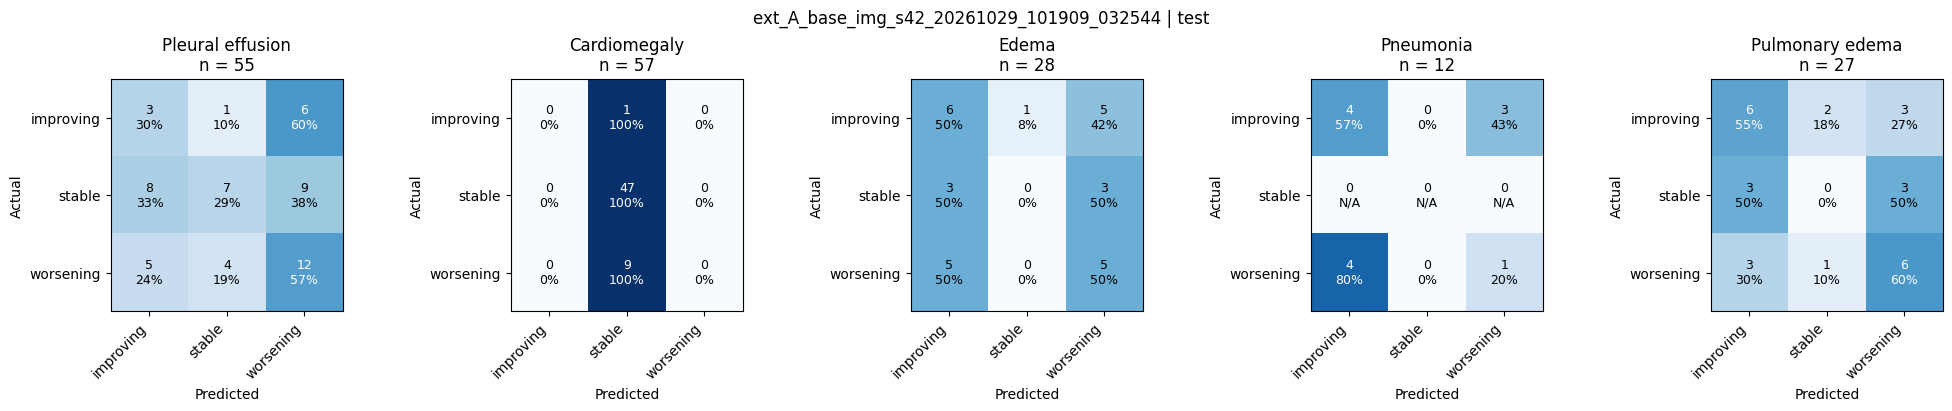

A2_base_diag_img


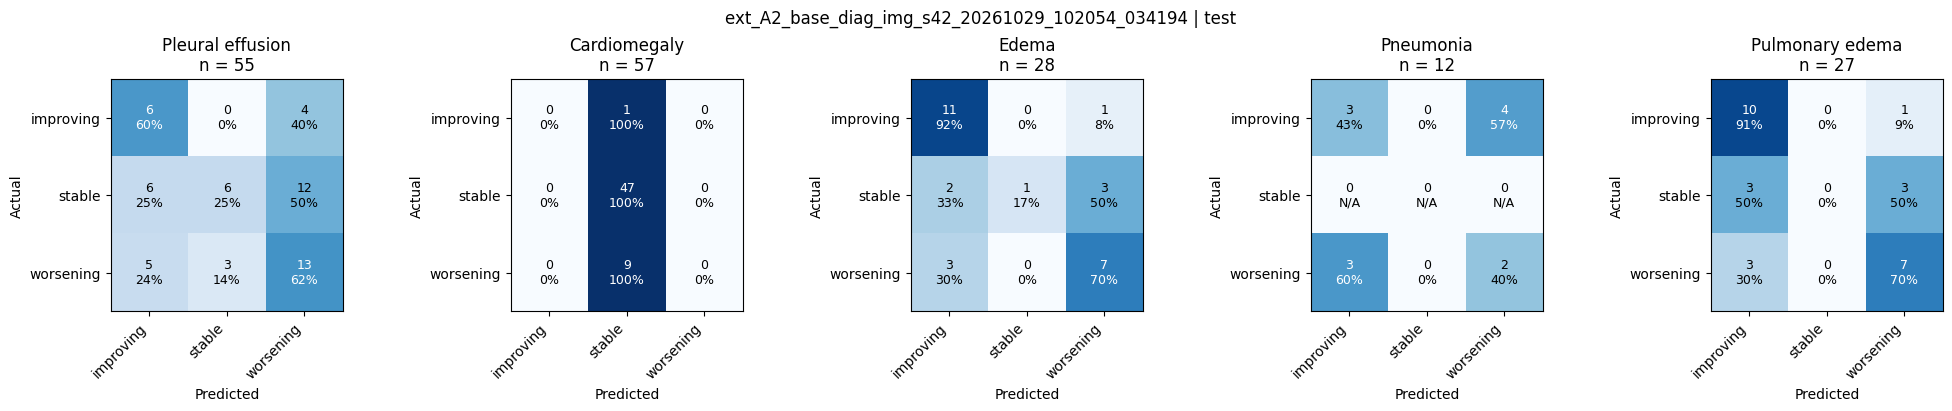

E_new_img_tab_shuffled


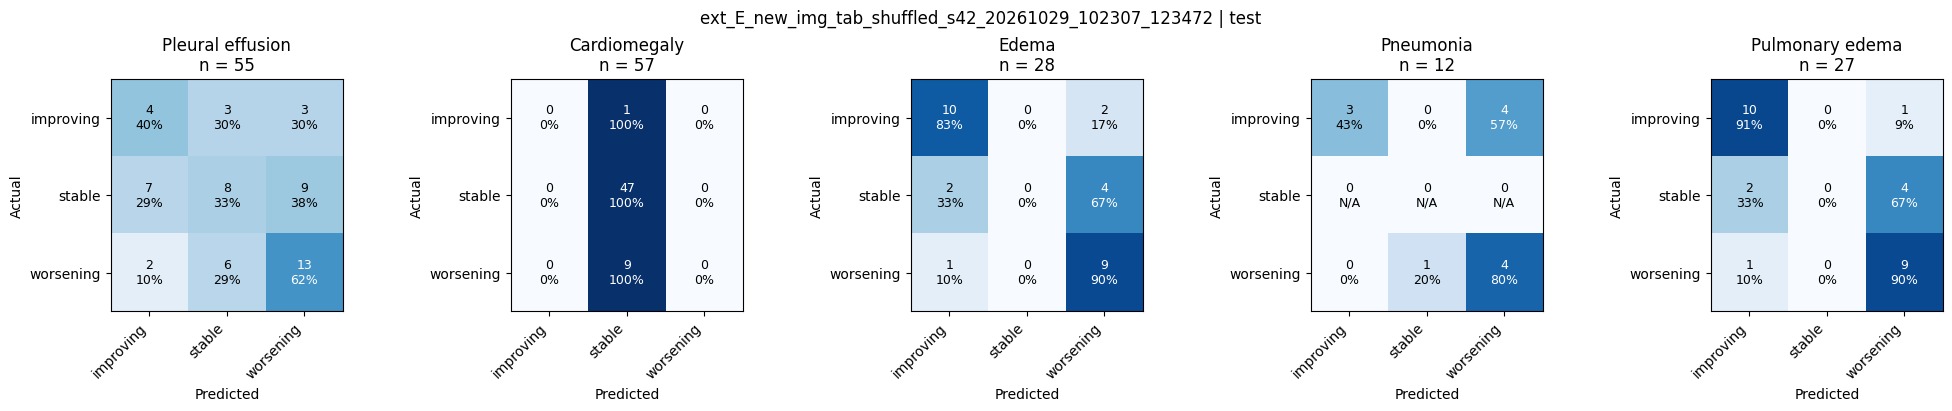

B_base_img_tab


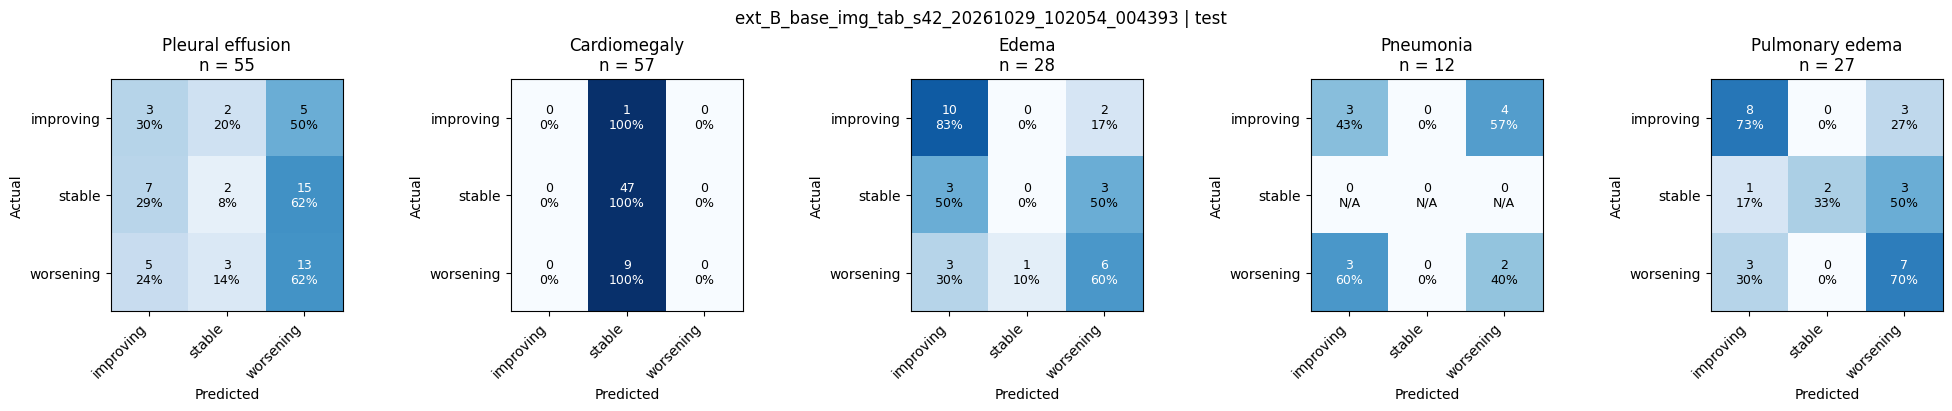

F_tab_nn


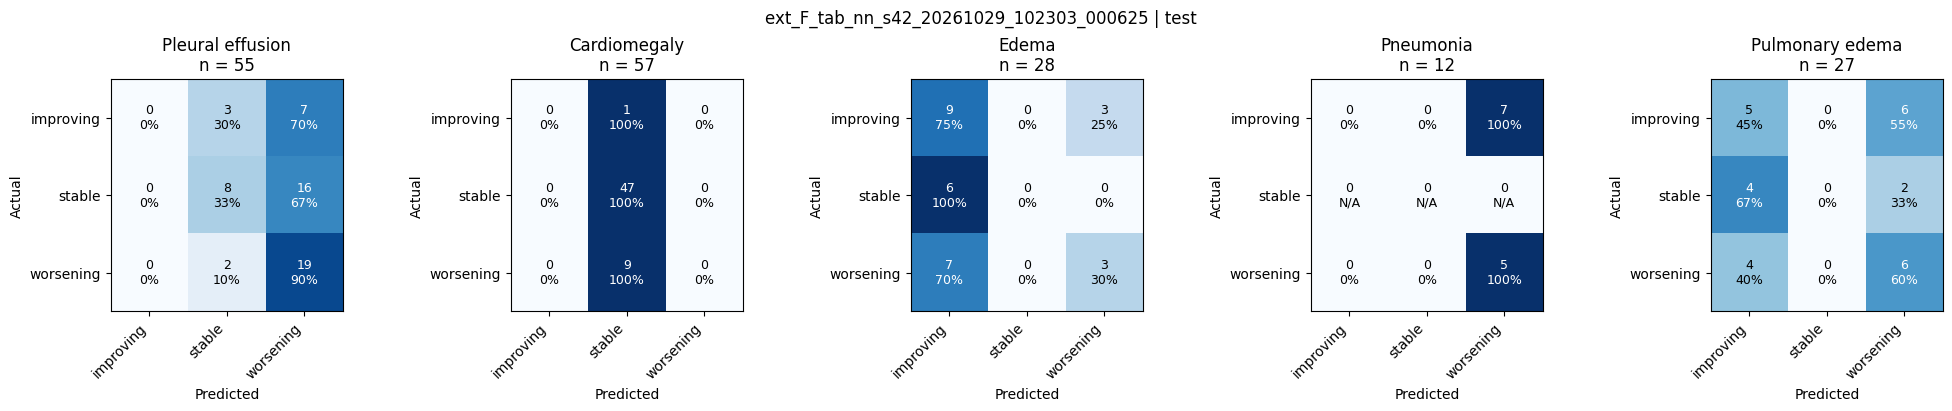

C_new_img


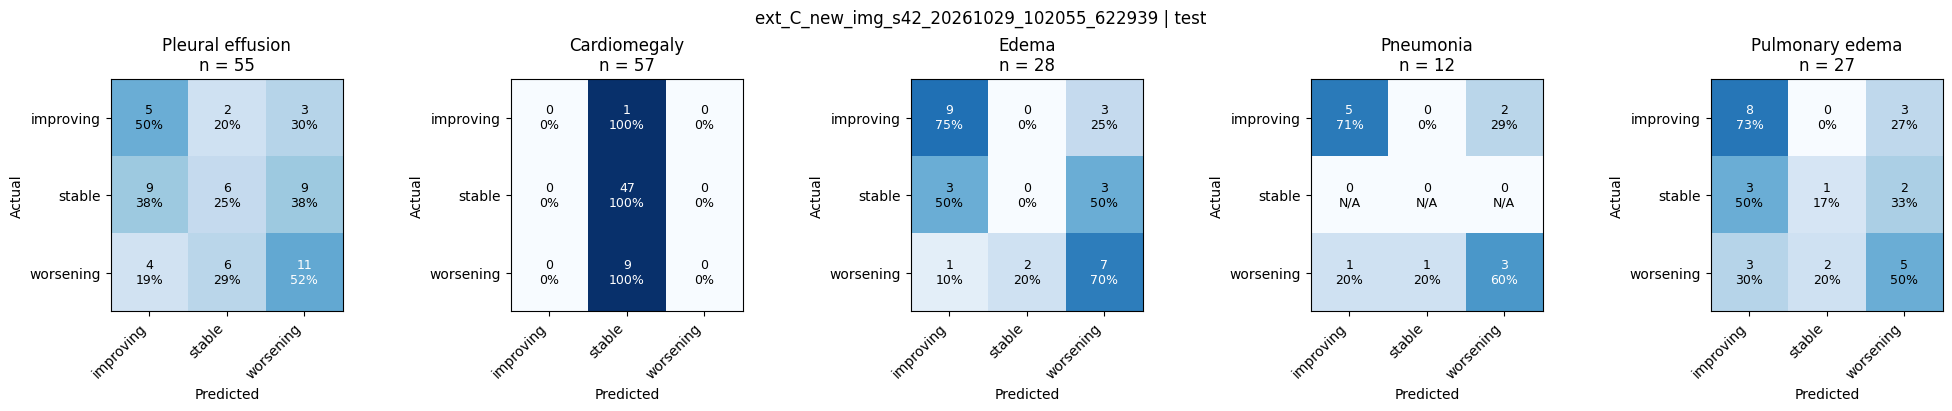

D_new_img_tab


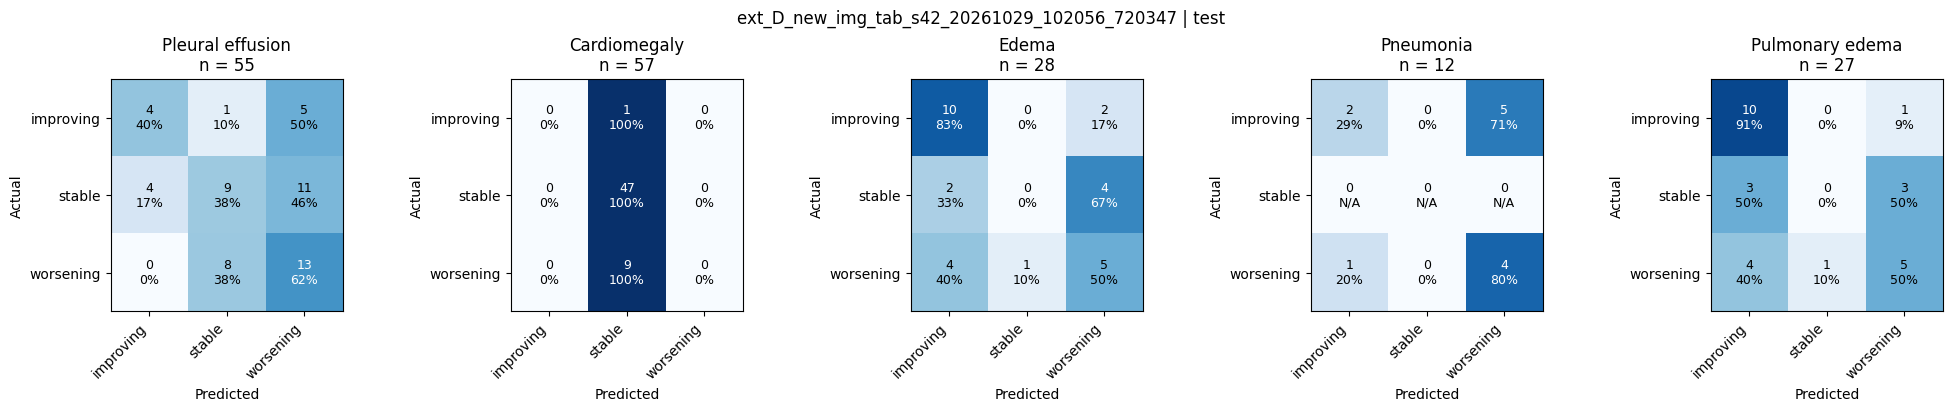

In [40]:
if ext_runs:
    all_ext = collect(ext_runs)
    print("VALIDATION (use for model choice)"); display(summary(all_ext, "val"))
    print("TEST (report once)");               display(summary(all_ext, "test"))
    for name, dirs in ext_runs.items():
        print(name); plot_confusions(dirs[0], "test")
else:
    print("Run experiments via EXT_TO_RUN first.")